# <a id='Index'>Photoreceptor arrays</a>
- [Voronoi](#voronoi)
- [NDD](#ndd)
- [Batch analysis](#batch)
- [Distribution models???](#models)

Ideas:
- Use kNDD and bound it by theoretical hex lattice and random distributions (bootstrapped à la JohnBall)
- Use pairwise NDD within all subtypes? Are there exclusion zones between pairs?

To do:
- [x] visualisation for single example
    - [x] Voronoi
    - [x] Llloyd's algorithm + bounding box
    - [ ] Should rewrite Lloyd's implementation to use scipy.spatial functions (findCentroid) and to bound search withing box properly
    - [ ] random distribution (should I account for physical size of cones?)
    - [x] support for tiff loading
    - [x] single class that allows flexible inputs to run in any photoreceptor subtype (based on napari segmentation or points)
- [x] batch analysis
    - [x] NDD distribution for each image
    - [x] NDDi distribution after Lloyd's relaxation (and final point distribution)
    - [x] summary bot to collect medians and to create meta-distributions by genotype
- [ ] integrate into napari
    - [ ] calculate and display Voronoi: might be easiest to calculate and then transform to a labels layer: [codehere](https://napari.org/stable/gallery/shapes_to_labels.html)
    - [ ] run by default as a final step during curation of segmentation AND to help with dotting.
        - need to revise analysis of UV cones and where possible merge U_missing.csv and U_seg_curated.tiff into a single U_points.csv
    - [ ] Animation of Lloyd's algorithm could be fun. Could be set up as a z-stack initially

In [2]:
import numpy as np
import pandas as pd
from scipy.stats import zscore
from scipy.stats import sem
from scipy import stats as st 
import scikit_posthocs
import scipy.spatial
import math
import IPython
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.font_manager as font_manager
import colorsys
import importlib
import svgutils
from svgutils.compose import *
import os.path
import time, sys, warnings
from tqdm.notebook import tqdm, trange
from scipy.stats import mannwhitneyu
from scipy.stats import kruskal
from skimage.io import imread
import ipywidgets
from IPython.display import display
from plotParams import *
from lloyd import *


pBGMenu = ipywidgets.Dropdown(options=['Light', 'Dark'],value='Dark',disabled=False, layout=ipywidgets.Layout(width='20%', height='40px'))
pBGLabel = ipywidgets.widgets.Label('Select plotting style', layout=ipywidgets.Layout(width='20%', height='30px'))
pBG = ipywidgets.widgets.VBox([pBGLabel,pBGMenu])
pBG

In [2]:
# baseColor = applyPlotStyle(pBGMenu.value)
# p2um = 63.64/1024


Plotting style is Dark


## Debugging code

In [ ]:
class NNDcalculator():
    '''
    Calculates NND (nearest-neighbour distances) and idealized NND (after running Lloyd's algorithm) using napari points or labels layer
    Created by Angueyra (Jan 2023)
    '''

    def __init__(self, dPath = '', celltype = 'U', datatype = 'points', nIter = 20, saveLloyd = False, overwriteFlag = False, **kwargs):
        '''
        descriptionHere
        '''
        self.dPath = dPath
        self.celltype = celltype
        self.datatype = datatype
        if (datatype=='labels'):
            self.fPath = self.celltype + '_seg_curated.tiff'
        elif (datatype=='points'):
            if (self.celltype=='U'):
                self.fPath = 'U_missing.csv'
            else:
                self.fPath = self.celltype + '_points.csv'
        self.ifPath = self.celltype + '_lloyd.npy'
        self.N_mip = 'N_mip.tiff'
        self.p2um = 79.64/2048
        self.kN = 1
        self.nIter = nIter
        self.Centroids = self.getCentroids();
        if (np.size(self.Centroids)>0): # skip any calculations if filepath is empty
            self.vor = scipy.spatial.Voronoi(self.Centroids)
            self.kdt = scipy.spatial.KDTree(self.Centroids)
            self.nnd = self.calcNND()
            self.iCentroids = self.calcLloyd(nIter = self.nIter, overwriteFlag = overwriteFlag)
            self.ivor = scipy.spatial.Voronoi(self.iCentroids)
            self.ikdt = scipy.spatial.KDTree(self.iCentroids)
            self.innd = self.calcNNDi()
            if saveLloyd:
                self.saveLloyd()
        
    def getCentroids(self):
        # return empty array if file does not exist
        if (os.path.isfile(self.dPath + self.fPath)==False):
            warnings.warn('{0} does not exist'.format(self.dPath + self.fPath))
            Centroids = [];
        else:
            if (self.datatype=='points'): # assumes input is structured like a napari points layer
                df =  pd.read_csv(self.dPath + self.fPath)
                df = df.drop(columns = 'index')
                Centroids = df.to_numpy()
                Centroids = Centroids[:,[1,0]]
            elif(self.datatype=='labels'): # input is an image file akin to napari labels layer
                labelData = imread (self.dPath + self.fPath)
                Centroids = calculateCentroidsFromLabels(labelData)
        return Centroids
        
    def calcNND(self):
        nnd = self.findNND(self.Centroids, self.kdt, self.kN)
        return nnd

    def calcNNDi(self):
        nndi = self.findNND(self.iCentroids, self.ikdt, self.kN)
        return nndi
    
    @staticmethod
    def findNND(centroids, kdt, kN):
        # initialize emtpy arrays
        nnd = np.empty((len(centroids),kN))
        nnd[:]=np.NaN
        # find k nearest neighbor distances
        for n in range(0,len(centroids)):
            temp = kdt.query(centroids[n],kN+1)
            for k in range (0,kN):
                nnd[n,k] = temp[0][k+1]
        return nnd

    
    def calcLloyd(self,nIter=20, overwriteFlag = False):
        if ((os.path.isfile(self.dPath + self.ifPath)) & (overwriteFlag == False)):
            print('Loaded saved Lloyd relaxation')
            iCentroids = np.load(self.dPath + self.ifPath, allow_pickle=True)
        else:
            #start from original locations
            field = Field(self.Centroids, buffer = 20) 
            # # #start from center of the field
            # rng = np.random.default_rng()
            # rndCentroids = rng.integers(500,525, size=np.shape(self.Centroids))
            # field = Field(rndCentroids, buffer = 20) 
            with tqdm(total=nIter, file=sys.stdout) as progBar:
            # run Lloyd relaxation on the field of points
                for i in np.arange(0,nIter):
                    field.relax()
                    progBar.update(1)
            # get the resulting point positions
            iCentroids = field.get_points()
        return iCentroids
    
    def saveLloyd(self):
        np.save(self.dPath + self.ifPath, self.iCentroids)
        np.save(self.dPath + 'nnd.npy', self.nnd)
        np.save(self.dPath + 'innd.npy', self.innd)
        print('Saved results for {0}'.format(self.dPath))
    
    def plotAll(self):
        fH, axH = plt.subplots(2, 2, figsize= [24,24], gridspec_kw={'height_ratios': [5, 1]})
        axH[0,1].sharey(axH[0,0])
        axH[1,1].sharey(axH[1,0])
        self.plotVor(fH, axH[0,0]);
        self.plotLloyd(fH, axH[0,1]);
        self.plotNDD(fH,axH[1,0]);
        self.plotNDDLloyd(fH,axH[1,1]);
        fH.tight_layout()
        return fH, axH
        
    def plotVor(self, fH, axH, plotRegions = False):
        '''
        plotter for N_mip, U locations and voronoi partition
        '''

        pH = axH.imshow(imread(self.dPath + self.N_mip), cmap='bone')
        
        pH = axH.scatter(self.Centroids[:,0],self.Centroids[:,1], color=zfC[self.celltype], zorder=8, marker = 'o', s=50, edgecolor=baseColor, linewidth=0.5, alpha = 0.99);
        pH = scipy.spatial.voronoi_plot_2d(self.vor, ax = axH, show_points = False, show_vertices=False, line_colors=zfC[self.celltype], line_width=2, line_alpha=0.99, point_size=2)
        
        if plotRegions:
            regions, vertices = voronoi_finite_polygons_2d(self.vor)
            # colorize
            for region in regions:
                polygon = vertices[region]
                axH.fill(*zip(*polygon), alpha=0.2)
        
        fontLabels = formatFigureMain(fH, axH, pH);
        axH.set_xlabel('d ($\mu$m)', fontproperties=fontLabels)
        axH.set_ylabel('d ($\mu$m)', fontproperties=fontLabels)
        axH.set_xlim([-100,1124])
        axH.set_ylim([-100,1124])
        
        def p2umfx(x, pos): # formatter function to convert pixels to microns
            s = '{:.2f}'.format(np.round(x * self.p2um,decimals=2))
            return s

        axH.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(p2umfx))
        axH.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(p2umfx))
        return fH, axH
    
    def plotLloyd(self, fH, axH):
        '''
        plotter for N_mip, U locations and voronoi partition after Lloyd's relaxation
        '''

        pH = axH.imshow(imread(self.dPath + self.N_mip), cmap='bone')
        
        pH = axH.scatter(self.Centroids[:,0],self.Centroids[:,1], color=zfC[self.celltype], zorder=8, marker = 'o', s=50, edgecolor=baseColor, linewidth=0.5, alpha = .2);
        pH = scipy.spatial.voronoi_plot_2d(self.vor, ax = axH, show_points = False, show_vertices=False, line_colors=zfC[self.celltype], line_width=2, line_alpha=0.2, point_size=2)
        
        pH = axH.scatter(self.iCentroids[:,0],self.iCentroids[:,1], color='#FFFFFF', zorder=8, marker = 'o', s=50, edgecolor=baseColor, linewidth=0.5, alpha = .99);
        pH = scipy.spatial.voronoi_plot_2d(self.ivor, ax = axH, show_points = False, show_vertices=False, line_colors='#FFFFFF', line_width=2, line_alpha=0.99, point_size=2)
        
        # regions, vertices = voronoi_finite_polygons_2d(self.vor)
        # # colorize
        # for region in regions:
        #     polygon = vertices[region]
        #     plt.fill(*zip(*polygon), alpha=0.2)
        
        fontLabels = formatFigureMain(fH, axH, pH);
        axH.set_xlabel('d ($\mu$m)', fontproperties=fontLabels)
        axH.set_ylabel('d ($\mu$m)', fontproperties=fontLabels)
        axH.set_xlim([-100,1124])
        axH.set_ylim([-100,1124])
        
        def p2umfx(x, pos): # formatter function to convert pixels to microns
            s = '{:.2f}'.format(np.round(x * self.p2um,decimals=2))
            return s

        axH.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(p2umfx))
        axH.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(p2umfx))
        return fH, axH
    
    def plotNDD(self, fH, axH):
        '''
        plotter for NDD distribution
        '''
        for k in range (0,self.kN):
            pH = axH.hist(self.nnd[:,k]*self.p2um, bins=20, color=zfC[self.celltype], edgecolor=baseColor, linewidth=0.5, alpha = .8, histtype='stepfilled');
            
        axH.set_xlim([0,np.max((self.nnd*self.p2um)*1.2)])
        fontLabels = formatFigureMain(fH, axH, pH);
        axH.set_xlabel('nnd ($\mu$m)', fontproperties=fontLabels)
        axH.set_ylabel('counts', fontproperties=fontLabels)
        
        nndmedian = np.median(self.nnd[:,k])
        pH = axH.axvline(nndmedian*self.p2um, color = lighten_color(zfC[self.celltype],0.5), linestyle='--')
        
        # summarize using median
        print ('\n number of UV cones = {0}'.format(len(self.Centroids)))
        for k in range (0,self.kN):
            print ('Median for {0}-NDD (Raw):\t {1:.2f} pixels\t {2:.2f} um'.format(k+1,nndmedian,nndmedian*self.p2um))
            # print ('Median for {0}-NDD UV-cones (Lloyd):\t {1:.2f} pixels\t {2:.2f} um'.format(k+1,inndmedian,inndmedian*self.p2um))
    
    def plotNDDLloyd(self, fH, axH):
        '''
        plotter for NDD distribution after Lloyd's relaxation
        '''
        for k in range (0,self.kN):
            pH = axH.hist(self.nnd[:,k]*self.p2um, bins=20, color=zfC[self.celltype], edgecolor=baseColor, linewidth=0.5, alpha = .8, histtype='stepfilled');
            
            pH = axH.hist(self.innd[:,k]*self.p2um, bins=20, color='#FFFFFF', edgecolor=baseColor, linewidth=0.5, alpha = .8, histtype='stepfilled');
            
        axH.set_xlim([0,np.max((self.nnd*self.p2um)*1.2)])
        fontLabels = formatFigureMain(fH, axH, pH);
        axH.set_xlabel('nnd ($\mu$m)', fontproperties=fontLabels)
        axH.set_ylabel('counts', fontproperties=fontLabels)
        
        nndmedian = np.median(self.nnd[:,k])
        pH = axH.axvline(nndmedian*self.p2um, color = lighten_color(zfC[self.celltype],0.5), linestyle='--')

        
        inndmedian = np.median(self.innd[:,k])
        pH = axH.axvline(inndmedian*self.p2um, color = lighten_color('#ffffff',0.5), linestyle=':')
        
        # summarize using median
        for k in range (0,self.kN):
            print ('Median for {0}-NDD (Lloyd):\t {1:.2f} pixels\t {2:.2f} um'.format(k+1,inndmedian,inndmedian*self.p2um))

# Carinna New NND & Regularity index Calculation Code 

In [3]:
class NNDcalculator():
    '''
    Calculates NND (nearest-neighbour distances) and idealized NND (after running Lloyd's algorithm)
    using napari points or labels layer
    Created by Angueyra (Jan 2023)
    '''

    def __init__(self, dPath='', celltype='U', datatype='points', nIter=20, saveLloyd=False, overwriteFlag=False, **kwargs):
        '''
        descriptionHere
        '''
        self.dPath = dPath
        self.celltype = celltype
        self.datatype = datatype

        if (datatype == 'labels'):
            self.fPath = self.celltype + '_seg_curated.tiff'
        elif (datatype == 'points'):
            if (self.celltype == 'U'):
                self.fPath = 'U_missing.csv'
            else:
                self.fPath = self.celltype + '_points.csv'

        self.ifPath = self.celltype + '_lloyd.npy'
        self.N_mip = 'N_mip.tiff'
        self.p2um = 79.64/2048
        self.kN = 1
        self.nIter = nIter

        self.Centroids = self.getCentroids()

        if (np.size(self.Centroids) > 0):  # skip any calculations if filepath is empty
            self.vor = scipy.spatial.Voronoi(self.Centroids)
            self.kdt = scipy.spatial.KDTree(self.Centroids)

            self.nnd = self.calcNND()

            self.iCentroids = self.calcLloyd(nIter=self.nIter, overwriteFlag=overwriteFlag)
            self.ivor = scipy.spatial.Voronoi(self.iCentroids)
            self.ikdt = scipy.spatial.KDTree(self.iCentroids)

            self.innd = self.calcNNDi()

            # NEW: Regularity index (unitless; pixels vs um cancels out)
            self.ri = self.calcRegularityIndex(self.nnd, ddof=1)     # raw RI
            self.iri = self.calcRegularityIndex(self.innd, ddof=1)   # Lloyd RI (optional)

            if saveLloyd:
                self.saveLloyd()

    def getCentroids(self):
        # return empty array if file does not exist
        if (os.path.isfile(self.dPath + self.fPath) == False):
            warnings.warn('{0} does not exist'.format(self.dPath + self.fPath))
            Centroids = []
        else:
            if (self.datatype == 'points'):  # assumes input is structured like a napari points layer
                df = pd.read_csv(self.dPath + self.fPath)
                df = df.drop(columns='index')
                Centroids = df.to_numpy()
                Centroids = Centroids[:, [1, 0]]
            elif (self.datatype == 'labels'):  # input is an image file akin to napari labels layer
                labelData = imread(self.dPath + self.fPath)
                Centroids = calculateCentroidsFromLabels(labelData)
        return Centroids

    def calcNND(self):
        nnd = self.findNND(self.Centroids, self.kdt, self.kN)
        return nnd

    def calcNNDi(self):
        nndi = self.findNND(self.iCentroids, self.ikdt, self.kN)
        return nndi

    # NEW
    def calcRegularityIndex(self, nnd, ddof=1):
        """
        Regularity Index (RI) = mean(NND) / std(NND)
        Returns np.nan if std is 0 or input is empty.
        """
        x = np.asarray(nnd, dtype=float).ravel()
        x = x[~np.isnan(x)]
        if x.size == 0:
            return np.nan
        mu = np.mean(x)
        sigma = np.std(x, ddof=ddof)
        return mu / sigma if sigma > 0 else np.nan

    @staticmethod
    def findNND(centroids, kdt, kN):
        # initialize empty arrays
        nnd = np.empty((len(centroids), kN))
        nnd[:] = np.NaN
        # find k nearest neighbor distances
        for n in range(0, len(centroids)):
            temp = kdt.query(centroids[n], kN + 1)
            for k in range(0, kN):
                nnd[n, k] = temp[0][k + 1]
        return nnd

    def calcLloyd(self, nIter=20, overwriteFlag=False):
        if ((os.path.isfile(self.dPath + self.ifPath)) & (overwriteFlag == False)):
            print('Loaded saved Lloyd relaxation')
            iCentroids = np.load(self.dPath + self.ifPath, allow_pickle=True)
        else:
            # start from original locations
            field = Field(self.Centroids, buffer=20)

            with tqdm(total=nIter, file=sys.stdout) as progBar:
                # run Lloyd relaxation on the field of points
                for i in np.arange(0, nIter):
                    field.relax()
                    progBar.update(1)

            # get the resulting point positions
            iCentroids = field.get_points()
        return iCentroids

    def saveLloyd(self):
        # Lloyd centroids
        np.save(self.dPath + self.ifPath, self.iCentroids)

        # NEW: save with celltype prefix (matches your downstream loading code)
        np.save(self.dPath + f'{self.celltype}_nnd.npy', self.nnd)
        np.save(self.dPath + f'{self.celltype}_innd.npy', self.innd)

        # NEW: save RI values
        np.save(self.dPath + f'{self.celltype}_ri.npy', np.array([self.ri]))
        np.save(self.dPath + f'{self.celltype}_iri.npy', np.array([self.iri]))

        # OPTIONAL: also save legacy names for backward compatibility
        np.save(self.dPath + 'nnd.npy', self.nnd)
        np.save(self.dPath + 'innd.npy', self.innd)

        print('Saved results for {0}'.format(self.dPath))

    def plotAll(self):
        fH, axH = plt.subplots(2, 2, figsize=[24, 24], gridspec_kw={'height_ratios': [5, 1]})
        axH[0, 1].sharey(axH[0, 0])
        axH[1, 1].sharey(axH[1, 0])
        self.plotVor(fH, axH[0, 0])
        self.plotLloyd(fH, axH[0, 1])
        self.plotNDD(fH, axH[1, 0])
        self.plotNDDLloyd(fH, axH[1, 1])
        fH.tight_layout()
        return fH, axH

    def plotVor(self, fH, axH, plotRegions=False):
        '''
        plotter for N_mip, U locations and voronoi partition
        '''
        pH = axH.imshow(imread(self.dPath + self.N_mip), cmap='bone')

        pH = axH.scatter(self.Centroids[:, 0], self.Centroids[:, 1], color=zfC[self.celltype],
                         zorder=8, marker='o', s=50, edgecolor=baseColor, linewidth=0.5, alpha=0.99)
        pH = scipy.spatial.voronoi_plot_2d(self.vor, ax=axH, show_points=False, show_vertices=False,
                                          line_colors=zfC[self.celltype], line_width=2, line_alpha=0.99, point_size=2)

        if plotRegions:
            regions, vertices = voronoi_finite_polygons_2d(self.vor)
            for region in regions:
                polygon = vertices[region]
                axH.fill(*zip(*polygon), alpha=0.2)

        fontLabels = formatFigureMain(fH, axH, pH)
        axH.set_xlabel('d ($$\mu$$m)', fontproperties=fontLabels)
        axH.set_ylabel('d ($$\mu$$m)', fontproperties=fontLabels)
        axH.set_xlim([-100, 1124])
        axH.set_ylim([-100, 1124])

        def p2umfx(x, pos):
            s = '{:.2f}'.format(np.round(x * self.p2um, decimals=2))
            return s

        axH.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(p2umfx))
        axH.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(p2umfx))
        return fH, axH

    def plotLloyd(self, fH, axH):
        '''
        plotter for N_mip, U locations and voronoi partition after Lloyd's relaxation
        '''
        pH = axH.imshow(imread(self.dPath + self.N_mip), cmap='bone')

        pH = axH.scatter(self.Centroids[:, 0], self.Centroids[:, 1], color=zfC[self.celltype],
                         zorder=8, marker='o', s=50, edgecolor=baseColor, linewidth=0.5, alpha=.2)
        pH = scipy.spatial.voronoi_plot_2d(self.vor, ax=axH, show_points=False, show_vertices=False,
                                          line_colors=zfC[self.celltype], line_width=2, line_alpha=0.2, point_size=2)

        pH = axH.scatter(self.iCentroids[:, 0], self.iCentroids[:, 1], color='#FFFFFF',
                         zorder=8, marker='o', s=50, edgecolor=baseColor, linewidth=0.5, alpha=.99)
        pH = scipy.spatial.voronoi_plot_2d(self.ivor, ax=axH, show_points=False, show_vertices=False,
                                          line_colors='#FFFFFF', line_width=2, line_alpha=0.99, point_size=2)

        fontLabels = formatFigureMain(fH, axH, pH)
        axH.set_xlabel('d ($$\mu$$m)', fontproperties=fontLabels)
        axH.set_ylabel('d ($$\mu$$m)', fontproperties=fontLabels)
        axH.set_xlim([-100, 1124])
        axH.set_ylim([-100, 1124])

        def p2umfx(x, pos):
            s = '{:.2f}'.format(np.round(x * self.p2um, decimals=2))
            return s

        axH.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(p2umfx))
        axH.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(p2umfx))
        return fH, axH

    def plotNDD(self, fH, axH):
        '''
        plotter for NDD distribution
        '''
        for k in range(0, self.kN):
            pH = axH.hist(self.nnd[:, k] * self.p2um, bins=20, color=zfC[self.celltype],
                          edgecolor=baseColor, linewidth=0.5, alpha=.8, histtype='stepfilled')

        axH.set_xlim([0, np.max((self.nnd * self.p2um) * 1.2)])
        fontLabels = formatFigureMain(fH, axH, pH)
        axH.set_xlabel('nnd ($$\mu$$m)', fontproperties=fontLabels)
        axH.set_ylabel('counts', fontproperties=fontLabels)

        nndmedian = np.median(self.nnd[:, k])
        pH = axH.axvline(nndmedian * self.p2um, color=lighten_color(zfC[self.celltype], 0.5), linestyle='--')

        print('\n number of UV cones = {0}'.format(len(self.Centroids)))
        for k in range(0, self.kN):
            print('Median for {0}-NDD (Raw):\t {1:.2f} pixels\t {2:.2f} um'.format(k + 1, nndmedian, nndmedian * self.p2um))
            print('Regularity Index (Raw):\t {0:.4f}'.format(self.ri))

    def plotNDDLloyd(self, fH, axH):
        '''
        plotter for NDD distribution after Lloyd's relaxation
        '''
        for k in range(0, self.kN):
            pH = axH.hist(self.nnd[:, k] * self.p2um, bins=20, color=zfC[self.celltype],
                          edgecolor=baseColor, linewidth=0.5, alpha=.8, histtype='stepfilled')

            pH = axH.hist(self.innd[:, k] * self.p2um, bins=20, color='#FFFFFF',
                          edgecolor=baseColor, linewidth=0.5, alpha=.8, histtype='stepfilled')

        axH.set_xlim([0, np.max((self.nnd * self.p2um) * 1.2)])
        fontLabels = formatFigureMain(fH, axH, pH)
        axH.set_xlabel('nnd ($$\mu$$m)', fontproperties=fontLabels)
        axH.set_ylabel('counts', fontproperties=fontLabels)

        nndmedian = np.median(self.nnd[:, k])
        pH = axH.axvline(nndmedian * self.p2um, color=lighten_color(zfC[self.celltype], 0.5), linestyle='--')

        inndmedian = np.median(self.innd[:, k])
        pH = axH.axvline(inndmedian * self.p2um, color=lighten_color('#ffffff', 0.5), linestyle=':')

        for k in range(0, self.kN):
            print('Median for {0}-NDD (Lloyd):\t {1:.2f} pixels\t {2:.2f} um'.format(k + 1, inndmedian, inndmedian * self.p2um))
            print('Regularity Index (Lloyd):\t {0:.4f}'.format(self.iri))

## <a id='batch'>Batch analysis</a>
- Starting with a one liner that calculates everything
- Will make into a for loop
- Will need an interator that compiles data across images


> [Back to index](#Index)

In [2]:
# get folder names
#Path for UNINJ
# dPath = 'D:/Analysis/F0Tbx2arescueHalo_20241003/s1CxOG/uninj/'
#path for INJRESCUE
dPath = "Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/"

fList = os.listdir(dPath)
fList = list(map(lambda st: '\'' + st + '/\',', fList))
# fList = list(map(lambda st: 'fPath = \'' + st + '/\'', fList))
print(*fList, sep = "\n")

'wt/',
'Tbx2aKO/',
'Tbx2bKO/',


## Old NND calculation with wrong conversion (uses A1R)

In [68]:
# #WILDTYPE (FOU) FILES
# dPath = "Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/wt/"
# fPath = [
# #                '20250425_2ahetinx_5d_m2G_tdT_L08_002/', #tear in retina omit (CH 2026)
#                 '20250425_2ahetinx_5d_m2G_tdT_L08_004/',
#                 '20250425_2ahetinx_5d_m2G_tdT_L09_002/',
#                 '20250425_2ahetinx_5d_m2G_tdT_L09_004/',
#                 '20250425_2ahetinx_5d_m2G_tdT_L10_002/',
#                 '20250425_2ahetinx_5d_m2G_tdT_L10_004/',
# #                 # '20250425_2ahetinx_5d_m2G_tdT_L11_002', too curved omit (CH 2026)
#                 '20250425_2ahetinx_5d_m2G_tdT_L12_002/',
# #                 # '20250425_2ahetinx_5d_m2G_tdT_L13_002', too curved omit (CH 2026)
# #                 # '20250425_5dpf_tbx2ahetinx_m2G_tdT_L01_002', #ISSUE
# #                 #'20250425_5dpf_tbx2ahetinx_m2G_tdT_L01_004', too curved omit (CH 2026)
# #                 #'20250425_5dpf_tbx2ahetinx_m2G_tdT_L02_002',  blurred omit (CH 2026)
#                 '20250425_5dpf_tbx2ahetinx_m2G_tdT_L02_004/',
#                 '20250425_5dpf_tbx2ahetinx_m2G_tdT_L03_002/',
#                 '20250425_5dpf_tbx2ahetinx_m2G_tdT_L03_004/',
#                 '20250425_5dpf_tbx2ahetinx_m2G_tdT_L04_002/',
#                 '20250425_5dpf_tbx2ahetinx_m2G_tdT_L04_004/',
# #                 # '20250425_5dpf_tbx2ahetinx_m2G_tdT_L05_002', #ISSUE 
#                 '20250425_5dpf_tbx2ahetinx_m2G_tdT_L05_004/',
#                 '20250425_5dpf_tbx2ahetinx_m2G_tdT_L06_002/',
#                 '20250425_5dpf_tbx2ahetinx_m2G_tdT_L07_002/',
#                 '20250425_5dpf_tbx2ahetinx_m2G_tdT_L07_004/',
#                 '220250818_5d_2ahetinx_tdT_m2G_L01_002/',
#                 '220250818_5d_2ahetinx_tdT_m2G_L02_002/',
#                 '220250818_5d_2ahetinx_tdT_m2G_L03_002/',
#                  '220250818_5d_2ahetinx_tdT_m2G_L05_002/',
#                 '220250818_5d_2ahetinx_tdT_m2G_L05_004/',
#                 '220250818_5d_2ahetinx_tdT_m2G_L06_002/',
#                 '220250818_5d_2ahetinx_tdT_m2G_L07_002/',
#                 '220250818_5d_2ahetinx_tdT_m2G_L08_002/',
#                 '220250818_5d_2ahetinx_tdT_m2G_L08_004/',
#                 '220250818_5d_2ahetinx_tdT_m2G_L010_002/',
#                 '220250818_5d_2ahetinx_tdT_m2G_L011_002/',
#                 '220250818_5d_2ahetinx_tdT_m2G_L011_006/',
# #                 # '220250817_5d_m2G_tdT_2ahetinx_L12_002/', #mip not found
#                 '220250817_5d_m2G_tdT_2ahetinx_L12_006/',
#                 '220250817_5d_m2G_tdT_2ahetinx_L13_002/',
#                 '220250817_5d_m2G_tdT_2ahetinx_L14_002/',
#                 '220250817_5d_m2G_tdT_2ahetinx_L14_006/',
# #                 # '220250723_2bhetinx_5d_tdT_m2G_L01_002',#no l seg curated 
# #                # '220250723_2bhetinx_5d_tdT_m2G_L01_004', #no l seg curated
# #                 # '220250723_2bhetinx_5d_tdT_m2G_L02_002',#no l seg curated
# #                 # '220250723_2bhetinx_5d_tdT_m2G_L02_004',#no l seg curated
#                 '220250723_2bhetinx_5d_tdT_m2G_L03_002/', 
#                 '220250723_2bhetinx_5d_tdT_m2G_L03_004/',
#                 '220250723_2bhetinx_5d_tdT_m2G_L04_002/',
#                 '220250723_2bhetinx_5d_tdT_m2G_L04_004/',
# #                 # '220250723_2bhetinx_5d_tdT_m2G_L06_002/', #holes omit (CH 2026)
# #                 # '220250723_2bhetinx_5d_tdT_m2G_L06_004/', #holes omit (CH 2026)
# #                 # '220250723_2bhetinx_5d_tdT_m2G_L08_002/', #curved omit (CH 2026)
#                 '220250723_2bhetinx_5d_tdT_m2G_L08_004/',
#                 '220250723_2bhetinx_5d_tdT_m2G_L09_002/',
# #                 # '220250723_2bhetinx_5d_tdT_m2G_L09_004/', #curved  omit (CH 2026)
# #                 # '220250723_2bhetinx_5d_tdT_m2G_L13_002/', #curved  omit (CH 2026)
# #                 # '220250723_2bhetinx_5d_tdT_m2G_L14_002/', #curved omit (CH 2026)
# #                 '220250723_2bhetinx_5d_tdT_m2G_L14_004/', #curated tiffs not there? 
# #                 # '220250723_2bhetinx_5d_tdT_m2G_L15_004/', #curved omit (CH 2026)
# #                 # '220250723_2bhetinx_5d_tdT_m2G_L16_002/', #curved omit (CH 2026)
# #                 # '220250723_2bhetinx_5d_tdT_m2G_L16_004/', #curved omit (CH 2026)
# #                 # '220250723_2bhetinx_5d_tdT_m2G_L18_002/',#curved omit (CH 2026)
# #                 # '220250723_2bhetinx_5d_tdT_m2G_L18_002/',#curved omit (CH 2026)
# #                 '220250723_2bhetinx_5d_tdT_m2G_L23_002/', #no l seg curated omit (CH 2026)
# #                 '220250723_2bhetinx_5d_tdT_m2G_L23_004/', #no l seg curated curated tiff not there? omit (CH 2026)
# #                 '220250723_2bhetinx_5d_tdT_m2G_L24_002/', #no l seg curated omit (CH 2026)
# #                 # '220250723_2bhetinx_5d_tdT_m2G_L25_002/', #no m mip omit (CH 2026)
#                 '220250723_2bhetinx_5d_tdT_m2G_L25_004/',
#         ]

# for filepath in fPath:
#     nnd = NNDcalculator(dPath = dPath + filepath, celltype = 'M', datatype = 'labels', bg = 'M_mip', nIter = 1000, saveLloyd = True, overwriteFlag = False) #NND for M Cones
#     nnd = NNDcalculator(dPath = dPath + filepath, celltype = 'L', datatype = 'labels', bg = 'L_mip', nIter = 1000, saveLloyd = True, overwriteFlag = False)  #NND for L Cones
    
# #TBX2B KO FILES
# dPath =  "Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/Tbx2bKO/"
# # fPath = [       # '220250723_2bhetinx_5d_tdT_m2G_L07_002/', l NND DONE (CH 2026) 
#                 # '220250723_2bhetinx_5d_tdT_m2G_L07_004', #curved -  omit from analyzed data (CH 2026)
#                  # '220250723_2bhetinx_5d_tdT_m2G_L26_004/', #no curated l seg
#                 '220250723_2bhetinx_5d_tdT_m2G_L26_002'/, #l NND DONE (CH 2026)
#                 '220250723_2bhetinx_5d_tdT_m2G_L27_002/', #l NND DONE (CH 2026)
#                 '220250723_2bhetinx_5d_tdT_m2G_L28_002/', #l NND DONE (CH 2026)
#                 '20251022_5d_2bhetinx_m2G_tdT_L24_002/',  #l NND DONE (CH 2026) 
#                 '20251022_5d_2bhetinx_m2G_tdT_L24_004/',  #l NND DONE (CH 2026) 
#                 '20251022_5d_2bhetinx_m2G_tdT_L26_002/',  #l NND DONE (CH 2026) 
#                 '20251022_5d_2bhetinx_m2G_tdT_L26_004/', #l NND DONE (CH 2026) kinda curved - omit (CH 2026)
#                 '20251022_5d_2bhetinx_m2G_tdT_L18_002/',  #l NND DONE (CH 2026) 
#                 '20251022_5d_2bhetinx_m2G_tdT_L18_004/',  #l NND DONE (CH 2026) 
#                 # '20251022_5d_tbx2bhetinx_m2G_tdT_L32_004', #curved and blurry -  omit from analyzed data (CH 2026)
#                 # '20251022_5d_tbx2bhetinx_m2G_tdT_L32_002',#too curved to analyze -  omit from analyzed data (CH 2026)
#                 # '20251022_5d_tbx2bhetinx_m2G_tdT_L32_004', #too curved to analyze -  omit from analyzed data (CH 2026)
#                 '20251022_5d_tbx2bhetinx_m2G_tdT_L34_002', # #redo GFP Quant Analysis 
#                 # '20251022_5d_tbx2bhetinx_m2G_tdT_L34_004', #too curved MIP - omit from analyzed data (CH 2026)  
#                 '20251022_5d_tbx2bhetinx_m2G_tdT_L38_002', # flat. 
#                 '20251022_5d_tbx2bhetinx_m2G_tdT_L38_004', # curved -  omit from analyzed data (CH 2026)
#                 '20251022_5d_tbx2bhetinx_m2G_tdT_L41_002/',  #l NND DONE (CH 2026) 
#                 # '20251022_5d_tbx2bhetinx_m2G_tdT_L41_004', #curved - stretched effect -  omit from analyzed data (CH 2026)
#                 # '20251022_5d_tbx2bhetinx_m2G_tdT_L42_002', #CURVED - stretched effect -  omit from analyzed data (CH 2026)
#                 # '20251022_5d_tbx2bhetinx_m2G_tdT_L42_004', #CURVED - stretched effect -  omit from analyzed data (CH 2026)
#         ]


# # USE THESE FILES FOR M CONE SPACING IN TBX2B MUTANTS ONLY! (RELAIBLE WAY TO REPORT M CONES WITHOUT DOUBLE POSITIVE CELLS)
# fPath = [
#         '20250123_5dpf_tbx2bhetinx_s2C_m2G_L03_002/',  
#         '20250123_5dpf_tbx2bhetinx_s2C_m2G_L03_004/', 
#         '220250807_5dpf_2bhetinx_s2C_m2G_L05_003/',
#         '220250807_5dpf_2bhetinx_s2C_m2G_L05_005/', #missing nnd? 
#         '220250807_5dpf_2bhetinx_s2C_m2G_L08_002/', #issue with S/M nnd
#         '220250807_5dpf_2bhetinx_s2C_m2G_L08_004/', 
#         '220250807_5dpf_2bhetinx_s2C_m2G_L11_002/', #missing folder - FIND IT AND RUN ANALYSIS ON IT
#         '220250807_5dpf_2bhetinx_s2C_m2G_L11_004/',
#         '220250807_5dpf_2bhetinx_s2C_m2G_L13_002/',
#         '220250807_5dpf_2bhetinx_s2C_m2G_L13_004/',
#         '20250123_5dpf_tbx2bhetinx_s2C_m2G_L03_002/',
#         '20250123_5dpf_tbx2bhetinx_s2C_m2G_L03_004/',
#         '220250807_5dpf_2bhetinx_s2C_m2G_L05_003/',
#         '220250807_5dpf_2bhetinx_s2C_m2G_L05_005/', #(UNCOMMENTED?)
#         '220250807_5dpf_2bhetinx_s2C_m2G_L08_002/',
#         '220250807_5dpf_2bhetinx_s2C_m2G_L08_004/',
#         '220250807_5dpf_2bhetinx_s2C_m2G_L11_002/', #(UNCOMMENTED?)
#         '220250807_5dpf_2bhetinx_s2C_m2G_L11_004/',
#         '220250807_5dpf_2bhetinx_s2C_m2G_L13_002/',
#         '220250807_5dpf_2bhetinx_s2C_m2G_L13_004/',
#         ]

for filepath in fPath:
    nnd = NNDcalculator(dPath = dPath + filepath, celltype = 'M', datatype = 'labels', bg = 'M_mip', nIter = 1000, saveLloyd = True, overwriteFlag = False) #NND for M Cones
#     nnd = NNDcalculator(dPath = dPath + filepath, celltype = 'L', datatype = 'labels', bg = 'L_mip', nIter = 1000, saveLloyd = True, overwriteFlag = False)  #NND for L Cones
    
#TBX2A KO FILES
dPath =  "Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/Tbx2aKO/"
fPath = [
    # '220250818_5d_2ahetinx_tdT_m2G_L04_002/',
    # '220250818_5d_2ahetinx_tdT_m2G_L09_002/',
    # '220250818_5d_2ahetinx_tdT_m2G_L09_006/',
    # '20260226_5d_Tbx2ahetinx_tdT_m2G_L01_002/', #_seg_curated.tiff does not exist
    '20260226_5d_Tbx2ahetinx_tdT_m2G_L01_004/',
    '20260226_5d_Tbx2ahetinx_tdT_m2G_L02_002/',
    '20260226_5d_Tbx2ahetinx_tdT_m2G_L02_004/',
    '20260226_5d_Tbx2ahetinx_tdT_m2G_L03_002/',
    '20260226_5d_Tbx2ahetinx_tdT_m2G_L03_004/',
    '20260226_5d_Tbx2ahetinx_tdT_m2G_L05_002/',
    '20260226_5d_Tbx2ahetinx_tdT_m2G_L05_004/',

        ]

for filepath in fPath:
    nnd = NNDcalculator(dPath = dPath + filepath, celltype = 'M', datatype = 'labels', bg = 'M_mip', nIter = 1000, saveLloyd = True, overwriteFlag = False) #NND for M Cones
    # nnd = NNDcalculator(dPath = dPath + filepath, celltype = 'L', datatype = 'labels', bg = 'L_mip', nIter = 1000, saveLloyd = True, overwriteFlag = False)  #NND for L Cones
     
    

nnd.plotAll();


Loaded saved Lloyd relaxation
Saved results for Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/Tbx2aKO/220250818_5d_2ahetinx_tdT_m2G_L04_002/
Loaded saved Lloyd relaxation
Saved results for Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/Tbx2aKO/220250818_5d_2ahetinx_tdT_m2G_L09_002/
Loaded saved Lloyd relaxation
Saved results for Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/Tbx2aKO/220250818_5d_2ahetinx_tdT_m2G_L09_006/


C:\Users\Carin\AppData\Local\Temp\ipykernel_28204\3362910709.py:54: UserWarning: Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/Tbx2aKO/20260226_5d_Tbx2ahetinx_tdT_m2G_L01_002/M_seg_curated.tiff does not exist
  warnings.warn('{0} does not exist'.format(self.dPath + self.fPath))


Loaded saved Lloyd relaxation
Saved results for Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/Tbx2aKO/20260226_5d_Tbx2ahetinx_tdT_m2G_L01_004/
Loaded saved Lloyd relaxation
Saved results for Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/Tbx2aKO/20260226_5d_Tbx2ahetinx_tdT_m2G_L02_002/
Loaded saved Lloyd relaxation
Saved results for Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/Tbx2aKO/20260226_5d_Tbx2ahetinx_tdT_m2G_L02_004/
Loaded saved Lloyd relaxation
Saved results for Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/Tbx2aKO/20260226_5d_Tbx2ahetinx_tdT_m2G_L03_002/
Loaded saved Lloyd relaxation
Saved results for Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/Tbx2aKO/20260226_5d_Tbx2ahetinx_tdT_m2G_L03_004/
Loaded saved Lloyd relaxation
Saved results for Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/Tbx2aKO/20260226_5d_Tbx2ahetinx_tdT_m2G_L05_002/
Load

ValueError: 
d ($$\mu$$m)
   ^
ParseException: Expected end of text, found '$'  (at char 3), (line:1, col:4)

Error in callback <function _draw_all_if_interactive at 0x00000247B2D7FCA0> (for post_execute):


ValueError: 
d ($$\mu$$m)
   ^
ParseException: Expected end of text, found '$'  (at char 3), (line:1, col:4)

ValueError: 
d ($$\mu$$m)
   ^
ParseException: Expected end of text, found '$'  (at char 3), (line:1, col:4)

<Figure size 2400x2400 with 4 Axes>

## New NND Calculation with AXR Conversion 

In [6]:
import os
import numpy as np

P2UM = 79.64/2048  # um per pixel (AXR conversion)

def run_one(dPath, filepath, celltype, bg, nIter=1000, overwriteFlag=False, datatype='labels'):
    folder = dPath + filepath

    print(f"\n[{filepath}]")
    print(f"  Step: compute NND for celltype={celltype} (bg={bg})")
    obj = NNDcalculator(
        dPath=folder,
        celltype=celltype,
        datatype=datatype,
        bg=bg,
        nIter=nIter,
        saveLloyd=True,
        overwriteFlag=overwriteFlag
    )

    # median NND (raw) in pixels and um
    nnd_pix = np.asarray(obj.nnd, dtype=float).ravel()
    nnd_pix = nnd_pix[~np.isnan(nnd_pix)]
    nnd_med_pix = np.median(nnd_pix) if nnd_pix.size else np.nan
    nnd_med_um = nnd_med_pix * P2UM

    # RI values
    ri = float(getattr(obj, "ri", np.nan))
    iri = float(getattr(obj, "iri", np.nan))

    print(f"  Step: summary -> median NND = {nnd_med_pix:.6g} px = {nnd_med_um:.6g} um")
    print(f"  Step: RI computed -> RI(raw)={ri:.6g}, RI(Lloyd)={iri:.6g}")

    # confirm saved files exist
    fn_nnd = os.path.join(folder, f"{celltype}_nnd.npy")
    fn_ri  = os.path.join(folder, f"{celltype}_ri.npy")
    print(f"  Step: saved? {os.path.exists(fn_nnd)}  {celltype}_nnd.npy")
    print(f"  Step: saved? {os.path.exists(fn_ri)}   {celltype}_ri.npy")

    return obj


# # -------------------------
# # WILDTYPE (FOU) FILES
# # -------------------------
# dPath = "Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/wt/"
# fPath = [
#     #                '20250425_2ahetinx_5d_m2G_tdT_L08_002/', #tear in retina omit (CH 2026)
#                 '20250425_2ahetinx_5d_m2G_tdT_L08_004/',
#                 '20250425_2ahetinx_5d_m2G_tdT_L09_002/',
#                 '20250425_2ahetinx_5d_m2G_tdT_L09_004/',
#                 '20250425_2ahetinx_5d_m2G_tdT_L10_002/',
#                 '20250425_2ahetinx_5d_m2G_tdT_L10_004/',
# #                 # '20250425_2ahetinx_5d_m2G_tdT_L11_002', too curved omit (CH 2026)
#                 '20250425_2ahetinx_5d_m2G_tdT_L12_002/',
# #                 # '20250425_2ahetinx_5d_m2G_tdT_L13_002', too curved omit (CH 2026)
# #                 # '20250425_5dpf_tbx2ahetinx_m2G_tdT_L01_002', #ISSUE
# #                 #'20250425_5dpf_tbx2ahetinx_m2G_tdT_L01_004', too curved omit (CH 2026)
# #                 #'20250425_5dpf_tbx2ahetinx_m2G_tdT_L02_002',  blurred omit (CH 2026)
#                 '20250425_5dpf_tbx2ahetinx_m2G_tdT_L02_004/',
#                 '20250425_5dpf_tbx2ahetinx_m2G_tdT_L03_002/',
#                 '20250425_5dpf_tbx2ahetinx_m2G_tdT_L03_004/',
#                 '20250425_5dpf_tbx2ahetinx_m2G_tdT_L04_002/',
#                 '20250425_5dpf_tbx2ahetinx_m2G_tdT_L04_004/',
# #                 # '20250425_5dpf_tbx2ahetinx_m2G_tdT_L05_002', #ISSUE 
#                 '20250425_5dpf_tbx2ahetinx_m2G_tdT_L05_004/',
#                 '20250425_5dpf_tbx2ahetinx_m2G_tdT_L06_002/',
#                 '20250425_5dpf_tbx2ahetinx_m2G_tdT_L07_002/',
#                 '20250425_5dpf_tbx2ahetinx_m2G_tdT_L07_004/',
#                 '220250818_5d_2ahetinx_tdT_m2G_L01_002/',
#                 '220250818_5d_2ahetinx_tdT_m2G_L02_002/',
#                 '220250818_5d_2ahetinx_tdT_m2G_L03_002/',
#                  '220250818_5d_2ahetinx_tdT_m2G_L05_002/',
#                 '220250818_5d_2ahetinx_tdT_m2G_L05_004/',
#                 '220250818_5d_2ahetinx_tdT_m2G_L06_002/',
#                 '220250818_5d_2ahetinx_tdT_m2G_L07_002/',
#                 '220250818_5d_2ahetinx_tdT_m2G_L08_002/',
#                 '220250818_5d_2ahetinx_tdT_m2G_L08_004/',
#                 '220250818_5d_2ahetinx_tdT_m2G_L010_002/',
#                 '220250818_5d_2ahetinx_tdT_m2G_L011_002/',
#                 '220250818_5d_2ahetinx_tdT_m2G_L011_006/',
# #                 # '220250817_5d_m2G_tdT_2ahetinx_L12_002/', #mip not found
#                 '220250817_5d_m2G_tdT_2ahetinx_L12_006/',
#                 '220250817_5d_m2G_tdT_2ahetinx_L13_002/',
#                 '220250817_5d_m2G_tdT_2ahetinx_L14_002/',
#                 '220250817_5d_m2G_tdT_2ahetinx_L14_006/',
# #                 # '220250723_2bhetinx_5d_tdT_m2G_L01_002',#no l seg curated 
# #                # '220250723_2bhetinx_5d_tdT_m2G_L01_004', #no l seg curated
# #                 # '220250723_2bhetinx_5d_tdT_m2G_L02_002',#no l seg curated
# #                 # '220250723_2bhetinx_5d_tdT_m2G_L02_004',#no l seg curated
#                 '220250723_2bhetinx_5d_tdT_m2G_L03_002/', 
#                 '220250723_2bhetinx_5d_tdT_m2G_L03_004/',
#                 '220250723_2bhetinx_5d_tdT_m2G_L04_002/',
#                 '220250723_2bhetinx_5d_tdT_m2G_L04_004/',
# #                 # '220250723_2bhetinx_5d_tdT_m2G_L06_002/', #holes omit (CH 2026)
# #                 # '220250723_2bhetinx_5d_tdT_m2G_L06_004/', #holes omit (CH 2026)
# #                 # '220250723_2bhetinx_5d_tdT_m2G_L08_002/', #curved omit (CH 2026)
#                 '220250723_2bhetinx_5d_tdT_m2G_L08_004/',
#                 '220250723_2bhetinx_5d_tdT_m2G_L09_002/',
# #                 # '220250723_2bhetinx_5d_tdT_m2G_L09_004/', #curved  omit (CH 2026)
# #                 # '220250723_2bhetinx_5d_tdT_m2G_L13_002/', #curved  omit (CH 2026)
# #                 # '220250723_2bhetinx_5d_tdT_m2G_L14_002/', #curved omit (CH 2026)
# #                 '220250723_2bhetinx_5d_tdT_m2G_L14_004/', #curated tiffs not there? 
# #                 # '220250723_2bhetinx_5d_tdT_m2G_L15_004/', #curved omit (CH 2026)
# #                 # '220250723_2bhetinx_5d_tdT_m2G_L16_002/', #curved omit (CH 2026)
# #                 # '220250723_2bhetinx_5d_tdT_m2G_L16_004/', #curved omit (CH 2026)
# #                 # '220250723_2bhetinx_5d_tdT_m2G_L18_002/',#curved omit (CH 2026)
# #                 # '220250723_2bhetinx_5d_tdT_m2G_L18_002/',#curved omit (CH 2026)
# #                 '220250723_2bhetinx_5d_tdT_m2G_L23_002/', #no l seg curated omit (CH 2026)
# #                 '220250723_2bhetinx_5d_tdT_m2G_L23_004/', #no l seg curated curated tiff not there? omit (CH 2026)
# #                 '220250723_2bhetinx_5d_tdT_m2G_L24_002/', #no l seg curated omit (CH 2026)
# #                 # '220250723_2bhetinx_5d_tdT_m2G_L25_002/', #no m mip omit (CH 2026)
#                 '220250723_2bhetinx_5d_tdT_m2G_L25_004/',
# ]

# print("\n==================== WT ====================")
# for filepath in fPath:
#     _ = run_one(dPath, filepath, celltype='M', bg='M_mip', nIter=1000, overwriteFlag=False)
#     _ = run_one(dPath, filepath, celltype='L', bg='L_mip', nIter=1000, overwriteFlag=False)


# # -------------------------
# # TBX2B KO FILES
# # -------------------------
# dPath = "Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/Tbx2bKO/"
# fPath = [
#                  '220250723_2bhetinx_5d_tdT_m2G_L07_002/', #l NND DONE (CH 2026) 
#                 # '220250723_2bhetinx_5d_tdT_m2G_L07_004', #curved -  omit from analyzed data (CH 2026)
#                  # '220250723_2bhetinx_5d_tdT_m2G_L26_004/', #no curated l seg
#                 '220250723_2bhetinx_5d_tdT_m2G_L26_002/', #l NND DONE (CH 2026)
#                 '220250723_2bhetinx_5d_tdT_m2G_L27_002/', #l NND DONE (CH 2026)
#                 '220250723_2bhetinx_5d_tdT_m2G_L28_002/', #l NND DONE (CH 2026)
#                 '20251022_5d_2bhetinx_m2G_tdT_L24_002/',  #l NND DONE (CH 2026) 
#                 '20251022_5d_2bhetinx_m2G_tdT_L24_004/',  #l NND DONE (CH 2026) 
#                 '20251022_5d_2bhetinx_m2G_tdT_L26_002/',  #l NND DONE (CH 2026) 
#                 '20251022_5d_2bhetinx_m2G_tdT_L26_004/', #l NND DONE (CH 2026) kinda curved - omit (CH 2026)
#                 '20251022_5d_2bhetinx_m2G_tdT_L18_002/',  #l NND DONE (CH 2026) 
#                 '20251022_5d_2bhetinx_m2G_tdT_L18_004/',  #l NND DONE (CH 2026) 
#                 # '20251022_5d_tbx2bhetinx_m2G_tdT_L32_004', #curved and blurry -  omit from analyzed data (CH 2026)
#                 # '20251022_5d_tbx2bhetinx_m2G_tdT_L32_002',#too curved to analyze -  omit from analyzed data (CH 2026)
#                 # '20251022_5d_tbx2bhetinx_m2G_tdT_L32_004', #too curved to analyze -  omit from analyzed data (CH 2026)
#                 '20251022_5d_tbx2bhetinx_m2G_tdT_L34_002', # #redo GFP Quant Analysis 
#                 # '20251022_5d_tbx2bhetinx_m2G_tdT_L34_004', #too curved MIP - omit from analyzed data (CH 2026)  
#                 '20251022_5d_tbx2bhetinx_m2G_tdT_L38_002', # flat. 
#                 '20251022_5d_tbx2bhetinx_m2G_tdT_L38_004', # curved -  omit from analyzed data (CH 2026)
#                 '20251022_5d_tbx2bhetinx_m2G_tdT_L41_002/',  #l NND DONE (CH 2026) 
#                 # '20251022_5d_tbx2bhetinx_m2G_tdT_L41_004', #curved - stretched effect -  omit from analyzed data (CH 2026)
#                 # '20251022_5d_tbx2bhetinx_m2G_tdT_L42_002', #CURVED - stretched effect -  omit from analyzed data (CH 2026)
#                 # '20251022_5d_tbx2bhetinx_m2G_tdT_L42_004', #CURVED - stretched effect -  omit from analyzed data (CH 2026)
# ]

# print("\n==================== tbx2b_KO ====================")
# for filepath in fPath:
#     _ = run_one(dPath, filepath, celltype='M', bg='M_mip', nIter=1000, overwriteFlag=False)
#     _ = run_one(dPath, filepath, celltype='L', bg='L_mip', nIter=1000, overwriteFlag=False)


# -------------------------
# TBX2A KO FILES
# -------------------------
dPath = "Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/Tbx2aKO/"
fPath = [
    '220250818_5d_2ahetinx_tdT_m2G_L04_002/',
    '220250818_5d_2ahetinx_tdT_m2G_L09_002/',
    '220250818_5d_2ahetinx_tdT_m2G_L09_006/',
    '20260226_5d_Tbx2ahetinx_tdT_m2G_L01_002/',
    '20260226_5d_Tbx2ahetinx_tdT_m2G_L01_004/',
    '20260226_5d_Tbx2ahetinx_tdT_m2G_L02_002/',
    '20260226_5d_Tbx2ahetinx_tdT_m2G_L02_004/',
    '20260226_5d_Tbx2ahetinx_tdT_m2G_L03_002/',
    '20260226_5d_Tbx2ahetinx_tdT_m2G_L03_004/',
    '20260226_5d_Tbx2ahetinx_tdT_m2G_L05_002/',
    '20260226_5d_Tbx2ahetinx_tdT_m2G_L05_004/',
]

print("\n==================== tbx2a_KO ====================")
last_obj = None
for filepath in fPath:
    _ = run_one(dPath, filepath, celltype='M', bg='M_mip', nIter=1000, overwriteFlag=False)
    last_obj = run_one(dPath, filepath, celltype='L', bg='L_mip', nIter=1000, overwriteFlag=False)

# Optional: plot the last one (matches your original behavior)
last_obj.plotAll()


==================== WT ====================

[20250425_2ahetinx_5d_m2G_tdT_L08_004/]
  Step: compute NND for celltype=M (bg=M_mip)
Loaded saved Lloyd relaxation
Saved results for Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/wt/20250425_2ahetinx_5d_m2G_tdT_L08_004/
  Step: summary -> median NND = 98.0115 px = 3.81134 um
  Step: RI computed -> RI(raw)=7.22769, RI(Lloyd)=8.96401
  Step: saved? True  M_nnd.npy
  Step: saved? True   M_ri.npy

[20250425_2ahetinx_5d_m2G_tdT_L08_004/]
  Step: compute NND for celltype=L (bg=L_mip)
Loaded saved Lloyd relaxation
Saved results for Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/wt/20250425_2ahetinx_5d_m2G_tdT_L08_004/
  Step: summary -> median NND = 86.1423 px = 3.34979 um
  Step: RI computed -> RI(raw)=6.46709, RI(Lloyd)=8.72934
  Step: saved? True  L_nnd.npy
  Step: saved? True   L_ri.npy

[20250425_2ahetinx_5d_m2G_tdT_L09_002/]
  Step: compute NND for celltype=M (bg=M_mip)
Loaded saved Lloyd relaxa

  0%|          | 0/1000 [00:00<?, ?it/s]

Saved results for Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/Tbx2bKO/20251022_5d_2bhetinx_m2G_tdT_L24_002/
  Step: summary -> median NND = 73.2102 px = 2.8469 um
  Step: RI computed -> RI(raw)=4.10423, RI(Lloyd)=7.92628
  Step: saved? True  M_nnd.npy
  Step: saved? True   M_ri.npy

[20251022_5d_2bhetinx_m2G_tdT_L24_002/]
  Step: compute NND for celltype=L (bg=L_mip)
Loaded saved Lloyd relaxation
Saved results for Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/Tbx2bKO/20251022_5d_2bhetinx_m2G_tdT_L24_002/
  Step: summary -> median NND = 87.9855 px = 3.42147 um
  Step: RI computed -> RI(raw)=6.68984, RI(Lloyd)=8.04174
  Step: saved? True  L_nnd.npy
  Step: saved? True   L_ri.npy

[20251022_5d_2bhetinx_m2G_tdT_L24_004/]
  Step: compute NND for celltype=M (bg=M_mip)


  0%|          | 0/1000 [00:00<?, ?it/s]

Saved results for Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/Tbx2bKO/20251022_5d_2bhetinx_m2G_tdT_L24_004/
  Step: summary -> median NND = 75.9658 px = 2.95406 um
  Step: RI computed -> RI(raw)=4.79932, RI(Lloyd)=7.10416
  Step: saved? True  M_nnd.npy
  Step: saved? True   M_ri.npy

[20251022_5d_2bhetinx_m2G_tdT_L24_004/]
  Step: compute NND for celltype=L (bg=L_mip)
Loaded saved Lloyd relaxation
Saved results for Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/Tbx2bKO/20251022_5d_2bhetinx_m2G_tdT_L24_004/
  Step: summary -> median NND = 86.7342 px = 3.37281 um
  Step: RI computed -> RI(raw)=6.94146, RI(Lloyd)=6.7759
  Step: saved? True  L_nnd.npy
  Step: saved? True   L_ri.npy

[20251022_5d_2bhetinx_m2G_tdT_L26_002/]
  Step: compute NND for celltype=M (bg=M_mip)


  0%|          | 0/1000 [00:00<?, ?it/s]

... (5 outputs left out)

  0%|          | 0/1000 [00:00<?, ?it/s]

Saved results for Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/Tbx2bKO/20251022_5d_2bhetinx_m2G_tdT_L18_004/
  Step: summary -> median NND = 90.4632 px = 3.51782 um
  Step: RI computed -> RI(raw)=4.46518, RI(Lloyd)=6.7853
  Step: saved? True  M_nnd.npy
  Step: saved? True   M_ri.npy

[20251022_5d_2bhetinx_m2G_tdT_L18_004/]
  Step: compute NND for celltype=L (bg=L_mip)
Loaded saved Lloyd relaxation
Saved results for Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/Tbx2bKO/20251022_5d_2bhetinx_m2G_tdT_L18_004/
  Step: summary -> median NND = 105.561 px = 4.1049 um
  Step: RI computed -> RI(raw)=6.77738, RI(Lloyd)=9.74936
  Step: saved? True  L_nnd.npy
  Step: saved? True   L_ri.npy

[20251022_5d_tbx2bhetinx_m2G_tdT_L34_002]
  Step: compute NND for celltype=M (bg=M_mip)


C:\Users\Carin\AppData\Local\Temp\ipykernel_28204\3362910709.py:54: UserWarning: Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/Tbx2bKO/20251022_5d_tbx2bhetinx_m2G_tdT_L34_002M_seg_curated.tiff does not exist
  warnings.warn('{0} does not exist'.format(self.dPath + self.fPath))


AttributeError: 'NNDcalculator' object has no attribute 'nnd'

In [ ]:
dPath = '/Users/angueyraaristjm/Documents/eelImaging/tempAnalysis/CRnr2e3F0s/xOGaCT/wt/'
fPath = [
    # '20220121_5dpf_xOG_aCT_wt_L01_002/',
    # '20220121_5dpf_xOG_aCT_wt_L02_002/',
    # '20220121_5dpf_xOG_aCT_wt_L02_004/',
    # '20220121_5dpf_xOG_aCT_wt_L03_002/',
    # '20220121_5dpf_xOG_aCT_wt_L03_004/', # no UV cones dotted
    # '20220121_5dpf_xOG_aCT_wt_L04_002/',
    # '20220121_5dpf_xOG_aCT_wt_L05_002/',
    # '20220121_5dpf_xOG_aCT_wt_L06_002/',
    # '20220121_5dpf_xOG_aCT_wt_L07_002/',
    # '20220121_5dpf_xOG_aCT_wt_L07_004/',
    # '20220121_5dpf_xOG_aCT_wt_L08_002/',
    # '20220121_5dpf_xOG_aCT_wt_L08_004/',
    # '20220121_5dpf_xOG_aCT_wt_L09_002/',
    # '20220121_5dpf_xOG_aCT_wt_L09_004/', # no UV cones dotted
    # '20220121_5dpf_xOG_aCT_wt_L10_002/',
    # '20220121_5dpf_xOG_aCT_wt_L10_004/',
    # '20220121_5dpf_xOG_aCT_wt_L11_002/', # no UV cones dotted
    # '20220121_5dpf_xOG_aCT_wt_L11_004/',
    # '20220121_5dpf_xOG_aCT_wt_L12_002/',
    # '20220121_5dpf_xOG_aCT_wt_L13_002/',
    # '20220121_5dpf_xOG_aCT_wt_L13_004/',
    # '20220121_5dpf_xOG_aCT_wt_L14_002/', # no UV cones dotted
    # '20220121_5dpf_xOG_aCT_wt_L15_002/',
    # '20220121_5dpf_xOG_aCT_wt_L16_002/',
]

for filepath in fPath:
    ndd = NNDcalculator(dPath = dPath + filepath, nIter = 1000, saveLloyd = True, overwriteFlag = False)

In [ ]:
dPath = '/Users/angueyraaristjm/Documents/eelImaging/tempAnalysis/CRnr2e3F0s/xOGaCT/nr2f1b/'
fPath = [
    '20220121_5dpf_xOG_aCT_nr2f1b_L01_002/',
    '20220121_5dpf_xOG_aCT_nr2f1b_L01_004/',
    # '20220121_5dpf_xOG_aCT_nr2f1b_L02_002/', # no UV cones dotted
    '20220121_5dpf_xOG_aCT_nr2f1b_L02_004/',
    '20220121_5dpf_xOG_aCT_nr2f1b_L03_002/',
    '20220121_5dpf_xOG_aCT_nr2f1b_L03_004/',
    # '20220121_5dpf_xOG_aCT_nr2f1b_L04_002/', # no UV cones dotted
    '20220121_5dpf_xOG_aCT_nr2f1b_L04_004/',
    # '20220121_5dpf_xOG_aCT_nr2f1b_L05_002/', # no UV cones dotted
    '20220121_5dpf_xOG_aCT_nr2f1b_L05_004/',
    # '20220121_5dpf_xOG_aCT_nr2f1b_L06_002/', # no UV cones dotted
    '20220121_5dpf_xOG_aCT_nr2f1b_L07_002/',
    '20220121_5dpf_xOG_aCT_nr2f1b_L08_002/',
    '20220121_5dpf_xOG_aCT_nr2f1b_L08_004/',
    '20220121_5dpf_xOG_aCT_nr2f1b_L09_002/',
    '20220121_5dpf_xOG_aCT_nr2f1b_L09_004/',
    '20220121_5dpf_xOG_aCT_nr2f1b_L10_002/',
    '20220121_5dpf_xOG_aCT_nr2f1b_L10_004/',
    '20220121_5dpf_xOG_aCT_nr2f1b_L11_002/',
    '20220121_5dpf_xOG_aCT_nr2f1b_L11_004/',
    # '20220121_5dpf_xOG_aCT_nr2f1b_L12_002/', # no UV cones dotted
]

for filepath in fPath:
    ndd = NNDcalculator(dPath = dPath + filepath, nIter = 1000, saveLloyd = True, overwriteFlag = False)

In [ ]:
dPath = '/Users/angueyraaristjm/Documents/eelImaging/tempAnalysis/CRnr2e3F0s/xOGaCT/nr2e3/'
fPath = [
    # '20220121_5dpf_xOG_aCT_nr2e3_L01_002/',
    # '20220121_5dpf_xOG_aCT_nr2e3_L01_004/',
    # '20220121_5dpf_xOG_aCT_nr2e3_L02_002/',
    # '20220121_5dpf_xOG_aCT_nr2e3_L02_004/',
    # '20220121_5dpf_xOG_aCT_nr2e3_L03_002/', # no UV cones dotted
    # '20220121_5dpf_xOG_aCT_nr2e3_L03_004/',
    # '20220121_5dpf_xOG_aCT_nr2e3_L05_002/',
    # '20220121_5dpf_xOG_aCT_nr2e3_L06_002/',
    # '20220121_5dpf_xOG_aCT_nr2e3_L06_004/',
    # '20220121_5dpf_xOG_aCT_nr2e3_L07_002/',
    # '20220121_5dpf_xOG_aCT_nr2e3_L07_004/', # no UV cones dotted
    # '20220121_5dpf_xOG_aCT_nr2e3_L08_002/',
    # '20220121_5dpf_xOG_aCT_nr2e3_L08_004/',
    # '20220121_5dpf_xOG_aCT_nr2e3_L09_002/',
    # '20220121_5dpf_xOG_aCT_nr2e3_L09_004/',
    # '20220121_5dpf_xOG_aCT_nr2e3_L10_002/',
    # '20220121_5dpf_xOG_aCT_nr2e3_L10_004/',
    # '20220121_5dpf_xOG_aCT_nr2e3_L11_002/', # empty UV cones file
    # '20220121_5dpf_xOG_aCT_nr2e3_L12_002/',
    # '20220121_5dpf_xOG_aCT_nr2e3_L12_004/', # no UV cones dotted
    # '20220121_5dpf_xOG_aCT_nr2e3_L14_002/', # no UV cones dotted
    # '20220121_5dpf_xOG_aCT_nr2e3_L15_002/',
    # '20220121_5dpf_xOG_aCT_nr2e3_L15_004/', # no UV cones dotted
    # '20220121_5dpf_xOG_aCT_nr2e3_L16_002/',
    # '20220121_5dpf_xOG_aCT_nr2e3_L16_004/', # something weird happened with Voronoi
]

for filepath in fPath:
    ndd = NNDcalculator(dPath = dPath + filepath, nIter = 1000, saveLloyd = True, overwriteFlag = False)

## Plot individual retinas

In [17]:
!jupyter labextension list

JupyterLab v3.6.1
C:\Users\Carin\mambaforge\envs\cellCounting\share\jupyter\labextensions
        ipycanvas v0.13.1 enabled ok
        ipyevents v2.0.1 enabled ok
        jupyterlab-jupytext v1.3.8+dev enabled ok (python, jupytext)
        jupyterlab_pygments v0.2.2 enabled ok (python, jupyterlab_pygments)
        @jupyter-widgets/jupyterlab-manager v5.0.5 enabled ok (python, jupyterlab_widgets)



In [7]:
dPath = "Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/wt/" #wildtype 
# dPath = "Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/Tbx2aKO/" #2a mutants
# dPath = "Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/Tbx2bKO/" #2b mutants 
fList = sorted([f for f in os.listdir(dPath) if not f.startswith('.')])

fLabel = ipywidgets.widgets.Label('Select filepath', layout=ipywidgets.Layout(width='10%', height='40px'))
fMenu = ipywidgets.Dropdown(options=fList,value=fList[0],disabled=False,layout=ipywidgets.Layout(width='30%', height='40px'))
fButton = ipywidgets.Button(description='plotNDD',disabled=False,button_style='',tooltip='plotNDD',
                            icon='check',layout=ipywidgets.Layout(width='20%', height='40px'))
fOut = ipywidgets.Output(layout=ipywidgets.Layout(width='40%', height='40px'))
def on_button_clicked(b):
    with fOut:
        fOut.clear_output()
        fPath = fMenu.value
        print(fPath)
fButton.on_click(on_button_clicked)
fSelect = ipywidgets.widgets.HBox([fLabel,fMenu,fButton,fOut])
fSelect

Loaded saved Lloyd relaxation

 number of UV cones = 226
Median for 1-NDD (Raw):	 117.37 pixels	 7.29 um
Median for 1-NDD (Lloyd):	 67.59 pixels	 4.20 um


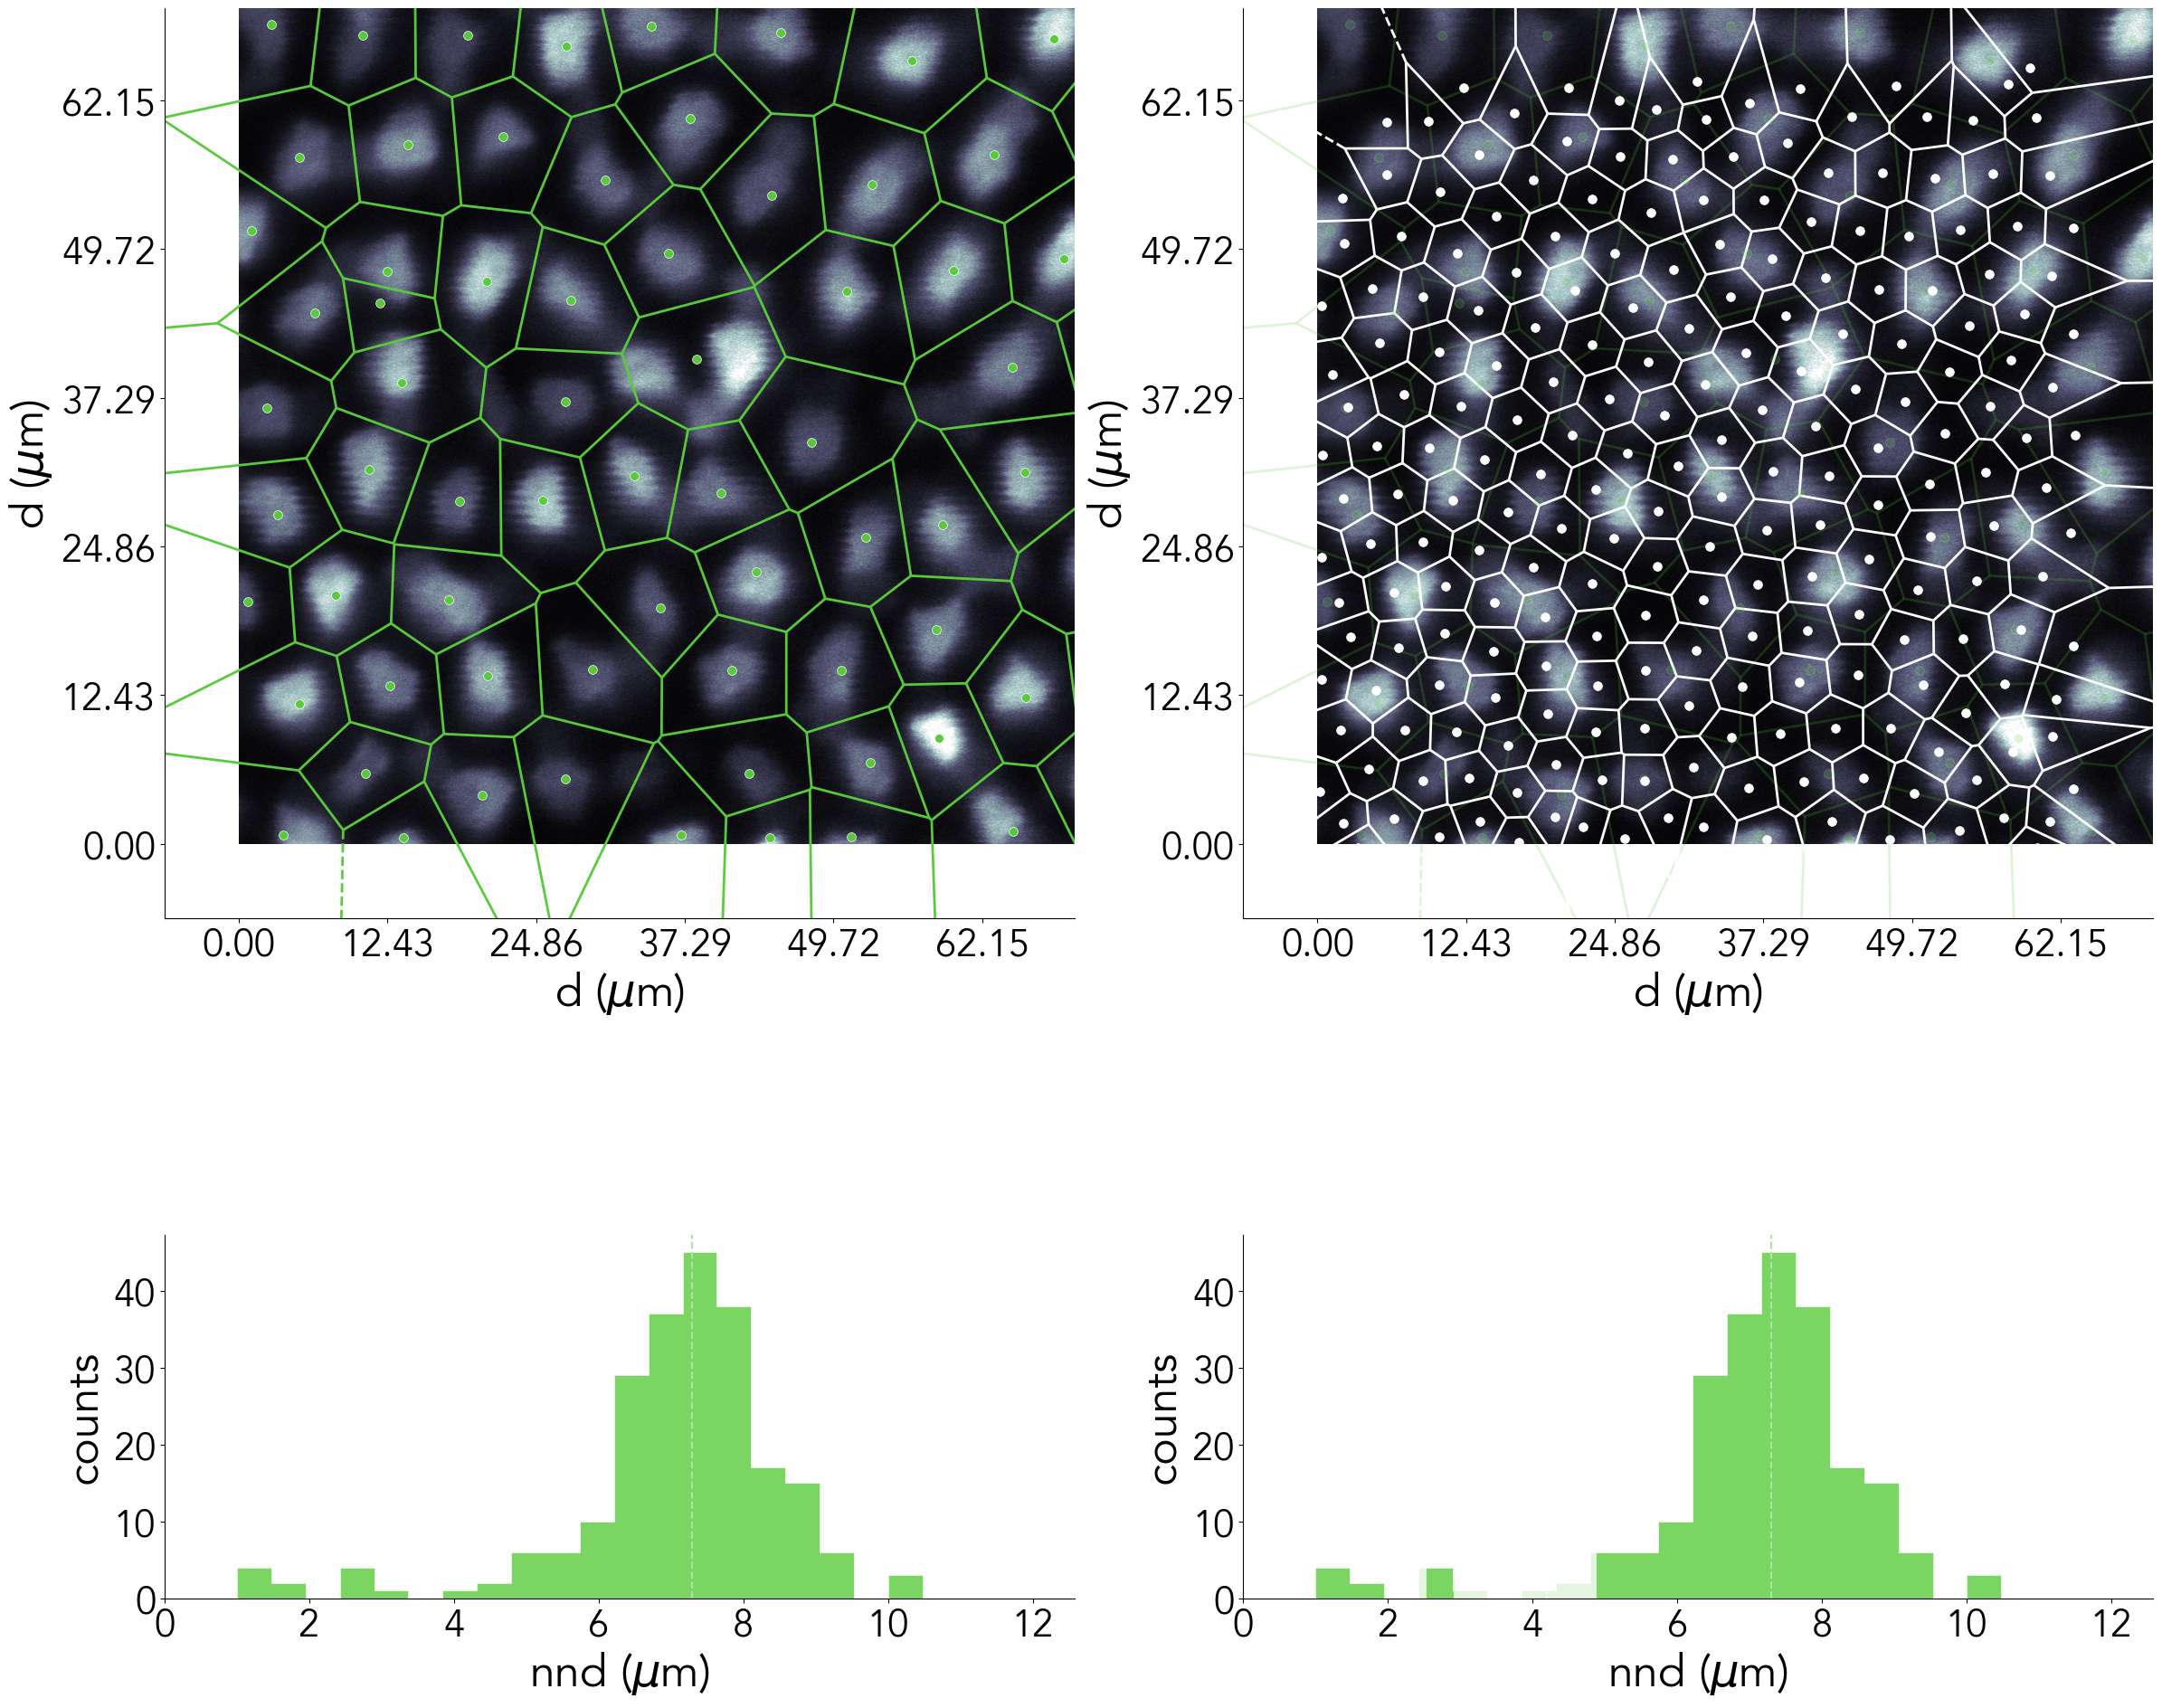

In [8]:
fPath = fMenu.value + '/'
ndd = NNDcalculator(dPath = dPath + fPath, celltype = 'M', datatype = 'labels', bg = 'M_mip')
ndd.plotAll();


In [ ]:

# dAnalysis = "/Users/angueyraaristjm/Library/CloudStorage/OneDrive-NationalInstitutesofHealth/zf/Analysis/CRtbx2F0s/xOGs1C/"
dPath = '/Users/angueyraaristjm/Documents/eelImaging/tempAnalysis/CRnr2e3F0s/xOGaCT/wt/'
fPath = '20220121_5dpf_xOG_aCT_wt_L01_002/'
fPath = '20220121_5dpf_xOG_aCT_wt_L02_002/'
fPath = '20220121_5dpf_xOG_aCT_wt_L02_004/'
fPath = '20220121_5dpf_xOG_aCT_wt_L03_002/'
fPath = '20220121_5dpf_xOG_aCT_wt_L04_002/'
fPath = '20220121_5dpf_xOG_aCT_wt_L05_002/'
fPath = '20220121_5dpf_xOG_aCT_wt_L06_002/'
fPath = '20220121_5dpf_xOG_aCT_wt_L07_002/'
fPath = '20220121_5dpf_xOG_aCT_wt_L07_004/'
fPath = '20220121_5dpf_xOG_aCT_wt_L08_002/'
fPath = '20220121_5dpf_xOG_aCT_wt_L08_004/'
fPath = '20220121_5dpf_xOG_aCT_wt_L09_002/'
fPath = '20220121_5dpf_xOG_aCT_wt_L10_002/'
#### fPath = '20220121_5dpf_xOG_aCT_wt_L10_004/' # incomplete dotting
fPath = '20220121_5dpf_xOG_aCT_wt_L11_004/'
fPath = '20220121_5dpf_xOG_aCT_wt_L12_002/'
#### fPath = '20220121_5dpf_xOG_aCT_wt_L13_002/' # incomplete dotting
fPath = '20220121_5dpf_xOG_aCT_wt_L13_004/'
#### fPath = '20220121_5dpf_xOG_aCT_wt_L15_002/' # incomplete dotting
#### fPath = '20220121_5dpf_xOG_aCT_wt_L16_002/' # incomplete dotting

ndd = NNDcalculator(dPath = dPath + fPath)
ndd.plotAll();


In [ ]:
dPath = '/Users/angueyraaristjm/Documents/eelImaging/tempAnalysis/CRnr2e3F0s/xOGaCT/nr2e3/'
fPath = '20220121_5dpf_xOG_aCT_nr2e3_L01_002/' # there's one UV cone not dotted that skews things
fPath = '20220121_5dpf_xOG_aCT_nr2e3_L01_004/'
#### fPath = '20220121_5dpf_xOG_aCT_nr2e3_L02_002/' # incomplete dotting
fPath = '20220121_5dpf_xOG_aCT_nr2e3_L02_004/'
fPath = '20220121_5dpf_xOG_aCT_nr2e3_L03_004/'
fPath = '20220121_5dpf_xOG_aCT_nr2e3_L05_002/'
fPath = '20220121_5dpf_xOG_aCT_nr2e3_L06_002/'
fPath = '20220121_5dpf_xOG_aCT_nr2e3_L06_004/'
fPath = '20220121_5dpf_xOG_aCT_nr2e3_L07_002/'
fPath = '20220121_5dpf_xOG_aCT_nr2e3_L08_002/'
fPath = '20220121_5dpf_xOG_aCT_nr2e3_L08_004/'
fPath = '20220121_5dpf_xOG_aCT_nr2e3_L09_002/'
fPath = '20220121_5dpf_xOG_aCT_nr2e3_L09_004/'
fPath = '20220121_5dpf_xOG_aCT_nr2e3_L10_002/'
fPath = '20220121_5dpf_xOG_aCT_nr2e3_L10_004/' # there's one UV cone not dotted that skews things
fPath = '20220121_5dpf_xOG_aCT_nr2e3_L12_002/'
fPath = '20220121_5dpf_xOG_aCT_nr2e3_L15_002/'
fPath = '20220121_5dpf_xOG_aCT_nr2e3_L16_002/'

dPath = '/Users/angueyraaristjm/Documents/eelImaging/tempAnalysis/CRnr2e3F0s/xOGaCT/nr2f1b/'
fPath = '20220121_5dpf_xOG_aCT_nr2f1b_L01_002/'
fPath = '20220121_5dpf_xOG_aCT_nr2f1b_L01_004/'
fPath = '20220121_5dpf_xOG_aCT_nr2f1b_L02_004/' # 2 UV cone missing clearly disrupt pattern
fPath = '20220121_5dpf_xOG_aCT_nr2f1b_L03_002/'
#### fPath = '20220121_5dpf_xOG_aCT_nr2f1b_L03_004/' # incomplete dotting
fPath = '20220121_5dpf_xOG_aCT_nr2f1b_L04_004/'
fPath = '20220121_5dpf_xOG_aCT_nr2f1b_L05_004/' # 1 UV cone missing
fPath = '20220121_5dpf_xOG_aCT_nr2f1b_L07_002/'
fPath = '20220121_5dpf_xOG_aCT_nr2f1b_L08_002/' # some missing in corner
fPath = '20220121_5dpf_xOG_aCT_nr2f1b_L08_004/'
fPath = '20220121_5dpf_xOG_aCT_nr2f1b_L09_002/'
fPath = '20220121_5dpf_xOG_aCT_nr2f1b_L09_004/'
fPath = '20220121_5dpf_xOG_aCT_nr2f1b_L10_002/'
fPath = '20220121_5dpf_xOG_aCT_nr2f1b_L10_004/'
fPath = '20220121_5dpf_xOG_aCT_nr2f1b_L11_002/'
fPath = '20220121_5dpf_xOG_aCT_nr2f1b_L11_004/'

ndd2 = NNDcalculator(dPath = dPath + fPath)
ndd2.plotAll();


## Collect NDD distributions across cells

In [ ]:
plotname = ''
fH, axH = plt.subplots(figsize= [9,12])

i = 0
for nndM,geneColor,geneMarker in zip([nndUMean_wt,nndUMean_nr2e3,nndUMean_nr2f1b],['#888888','#BF141B','#8888BB'],['o','o','o']):
    i = i+1
    jitter = np.random.randn(len(nndM))*0.05
    pH = plt.bar(i, np.mean(nndM), width=0.5, color=geneColor, linewidth = 2, edgecolor = geneColor);
    pH = plt.errorbar(i, np.mean(nndM), yerr = [[0],[np.std(nndM)]], ecolor=geneColor, elinewidth=3, capsize=8, capthick=3, zorder=9)
    pH = plt.scatter(np.ones(len(nndM))*i+jitter, nndM,
             color=lighten_color(geneColor,.75), zorder=8, marker = geneMarker, s=100, edgecolor=baseColor, linewidth=1, alpha = 0.6);

fontLabels = formatFigureMain(fH, axH, pH)
axH.set_xticks([1,2,3]);
axH.set_xticklabels(['wt','F0[nr2e3]','F0[nr2f1b]']);
axH.xaxis.set_tick_params(rotation=45)
# axH.set_ylim([0,300]); # tbx2
axH.set_ylabel('median UVndd  (um)', fontproperties=fontLabels)
plt.show()

### F&empty;[_tbx2a_:Tbx2a-Halo] in Nalou & Fou

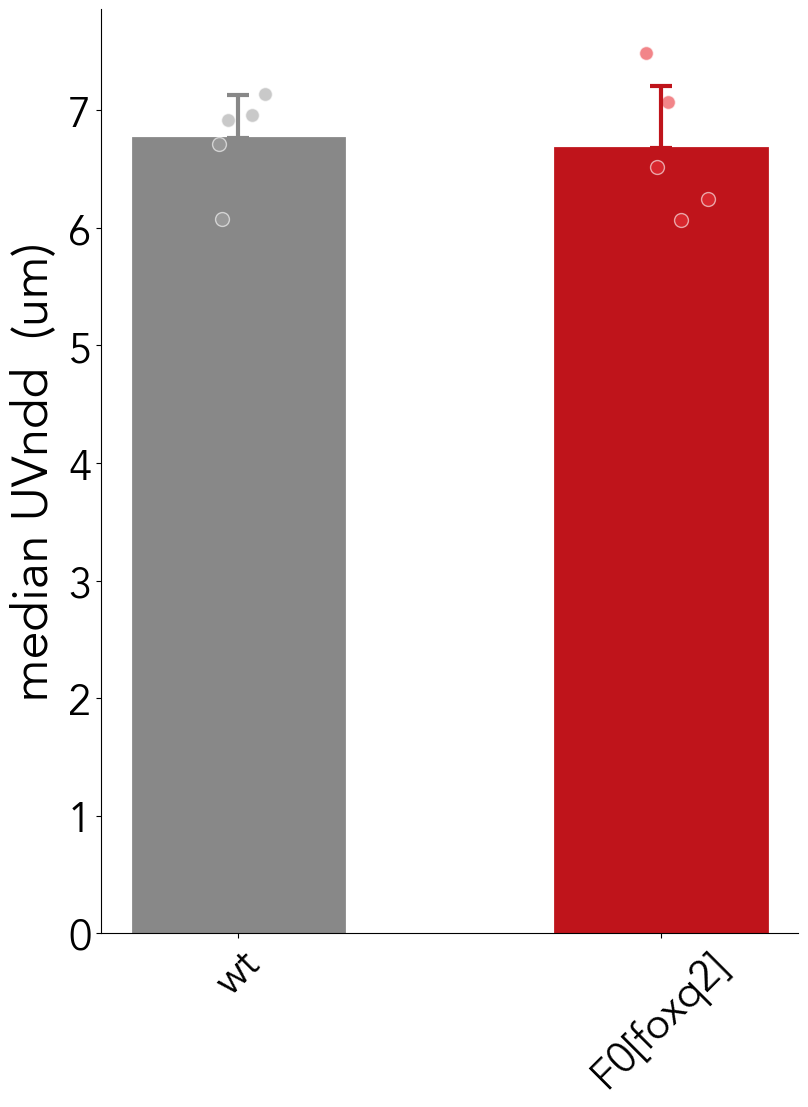

In [29]:
celltype = 'U'

#wildtype
dPath = "Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/wt/"
fPath = [
                '20250425_2ahetinx_5d_m2G_tdT_L08_002/', #tear in retina 
                '20250425_2ahetinx_5d_m2G_tdT_L08_004/',
                '20250425_2ahetinx_5d_m2G_tdT_L09_002/',
                '20250425_2ahetinx_5d_m2G_tdT_L09_004/',
                '20250425_2ahetinx_5d_m2G_tdT_L10_002/',
                '20250425_2ahetinx_5d_m2G_tdT_L10_004/',
                # '20250425_2ahetinx_5d_m2G_tdT_L11_002', too curved 
                '20250425_2ahetinx_5d_m2G_tdT_L12_002/',
                # '20250425_2ahetinx_5d_m2G_tdT_L13_002', too curved 
                # '20250425_5dpf_tbx2ahetinx_m2G_tdT_L01_002', #ISSUE
                #'20250425_5dpf_tbx2ahetinx_m2G_tdT_L01_004', too curved 
                #'20250425_5dpf_tbx2ahetinx_m2G_tdT_L02_002',  blurred 
                '20250425_5dpf_tbx2ahetinx_m2G_tdT_L02_004/',
                '20250425_5dpf_tbx2ahetinx_m2G_tdT_L03_002/',
                '20250425_5dpf_tbx2ahetinx_m2G_tdT_L03_004/',
                '20250425_5dpf_tbx2ahetinx_m2G_tdT_L04_002/',
                '20250425_5dpf_tbx2ahetinx_m2G_tdT_L04_004/',
                # '20250425_5dpf_tbx2ahetinx_m2G_tdT_L05_002', #ISSUE 
                '20250425_5dpf_tbx2ahetinx_m2G_tdT_L05_004/',
                '20250425_5dpf_tbx2ahetinx_m2G_tdT_L06_002/',
                '20250425_5dpf_tbx2ahetinx_m2G_tdT_L07_002/',
                '20250425_5dpf_tbx2ahetinx_m2G_tdT_L07_004/',
                '220250818_5d_2ahetinx_tdT_m2G_L01_002/',
                '220250818_5d_2ahetinx_tdT_m2G_L02_002/',
                '220250818_5d_2ahetinx_tdT_m2G_L03_002/',
                 '220250818_5d_2ahetinx_tdT_m2G_L05_002/',
                '220250818_5d_2ahetinx_tdT_m2G_L05_004/',
                '220250818_5d_2ahetinx_tdT_m2G_L06_002/',
                '220250818_5d_2ahetinx_tdT_m2G_L07_002/',
                '220250818_5d_2ahetinx_tdT_m2G_L08_002/',
                '220250818_5d_2ahetinx_tdT_m2G_L08_004/',
                '220250818_5d_2ahetinx_tdT_m2G_L010_002/',
                '220250818_5d_2ahetinx_tdT_m2G_L011_002/',
                '220250818_5d_2ahetinx_tdT_m2G_L011_006/',
                # '220250817_5d_m2G_tdT_2ahetinx_L12_002/', #mip not found
                '220250817_5d_m2G_tdT_2ahetinx_L12_006/',
                '220250817_5d_m2G_tdT_2ahetinx_L13_002/',
                '220250817_5d_m2G_tdT_2ahetinx_L14_002/',
                '220250817_5d_m2G_tdT_2ahetinx_L14_006/',
                # '220250723_2bhetinx_5d_tdT_m2G_L01_002',#no l seg curated
               # '220250723_2bhetinx_5d_tdT_m2G_L01_004', #no l seg curated
                # '220250723_2bhetinx_5d_tdT_m2G_L02_002',#no l seg curated
                # '220250723_2bhetinx_5d_tdT_m2G_L02_004',#no l seg curated
                '220250723_2bhetinx_5d_tdT_m2G_L03_002/', 
                '220250723_2bhetinx_5d_tdT_m2G_L03_004/',
                '220250723_2bhetinx_5d_tdT_m2G_L04_002/',
                '220250723_2bhetinx_5d_tdT_m2G_L04_004/',
                # '220250723_2bhetinx_5d_tdT_m2G_L06_002/', #holes
                # '220250723_2bhetinx_5d_tdT_m2G_L06_004/', #holes
                # '220250723_2bhetinx_5d_tdT_m2G_L08_002/', #curved
                '220250723_2bhetinx_5d_tdT_m2G_L08_004/',
                '220250723_2bhetinx_5d_tdT_m2G_L09_002/',
                # '220250723_2bhetinx_5d_tdT_m2G_L09_004/', #curved
                # '220250723_2bhetinx_5d_tdT_m2G_L13_002/', #curved
                # '220250723_2bhetinx_5d_tdT_m2G_L14_002/', #curved
                '220250723_2bhetinx_5d_tdT_m2G_L14_004/', #curated tiffs not there? 
                # '220250723_2bhetinx_5d_tdT_m2G_L15_004/', #curved
                # '220250723_2bhetinx_5d_tdT_m2G_L16_002/', #curved
                # '220250723_2bhetinx_5d_tdT_m2G_L16_004/', #curved
                # '220250723_2bhetinx_5d_tdT_m2G_L18_002/',#curved
                # '220250723_2bhetinx_5d_tdT_m2G_L18_002/',#curved
                '220250723_2bhetinx_5d_tdT_m2G_L23_002/', #no l seg curated
                '220250723_2bhetinx_5d_tdT_m2G_L23_004/', #no l seg curated curated tiff not there?
                '220250723_2bhetinx_5d_tdT_m2G_L24_002/', #no l seg curated
                # '220250723_2bhetinx_5d_tdT_m2G_L25_002/', #no m mip
                '220250723_2bhetinx_5d_tdT_m2G_L25_004/',
]


nndUMean_wt = np.empty((len(fPath),1))
nndUMean_wt[:]=np.NaN
i=0;
for filepath in fPath:
    nnd = np.load(dPath + filepath + celltype + '_nnd.npy')
    nndUMean_wt[i,0] = np.median(nnd) * 79.64/2048
    i=i+1;

    #injectedrescue    
dPath = "Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/Tbx2bKO/"
fPath = [
                '220250723_2bhetinx_5d_tdT_m2G_L07_002',
                # '220250723_2bhetinx_5d_tdT_m2G_L07_004', #curved
                 # '220250723_2bhetinx_5d_tdT_m2G_L26_004', #no curated l seg
                '220250723_2bhetinx_5d_tdT_m2G_L26_002',
                '220250723_2bhetinx_5d_tdT_m2G_L27_002',
                '220250723_2bhetinx_5d_tdT_m2G_L28_002', 
]

nndUMean_foxq2 = np.empty((len(fPath),1))
nndUMean_foxq2[:]=np.NaN
i=0;
for filepath in fPath:
    nnd = np.load(dPath + filepath + celltype + '_nnd.npy')
    nndUMean_foxq2[i,0] = np.median(nnd) * 79.64/2048
    i=i+1;
    
plotname = ''
fH, axH = plt.subplots(figsize= [9,12])

i = 0
for nndM,geneColor,geneMarker in zip([nndUMean_wt,nndUMean_foxq2],['#888888','#BF141B'],['o','o']):
    i = i+1
    jitter = np.random.randn(len(nndM))*0.05
    pH = plt.bar(i, np.mean(nndM), width=0.5, color=geneColor, linewidth = 2, edgecolor = geneColor);
    pH = plt.errorbar(i, np.mean(nndM), yerr = [[0],[np.std(nndM)]], ecolor=geneColor, elinewidth=3, capsize=8, capthick=3, zorder=9)
    pH = plt.scatter(np.ones(len(nndM))*i+jitter, nndM,
             color=lighten_color(geneColor,.75), zorder=8, marker = geneMarker, s=100, edgecolor=baseColor, linewidth=1, alpha = 0.6);

fontLabels = formatFigureMain(fH, axH, pH)
axH.set_xticks([1,2]);
axH.set_xticklabels(['wt','F0[foxq2]']);
axH.xaxis.set_tick_params(rotation=45)
# axH.set_ylim([0,300]); # tbx2
axH.set_ylabel('median UVndd  (um)', fontproperties=fontLabels)
plt.show()

### NND Plotting for L cones in *tbx2* mutants

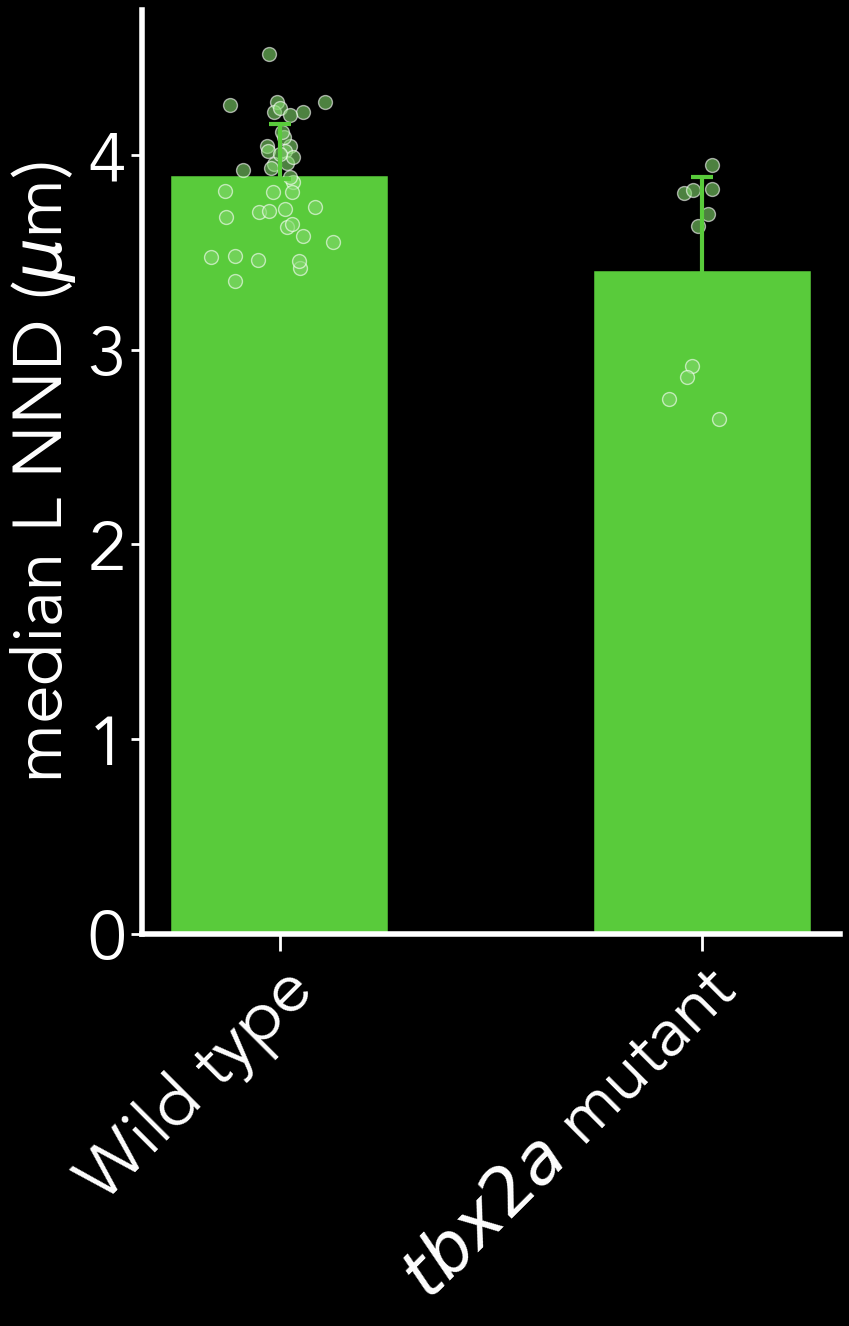

In [14]:

celltype = 'M'
# celltype = 'L'



#wildtype
dPath = "Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/wt/"
fPath = [
                # '20250425_2ahetinx_5d_m2G_tdT_L08_002/', #tear in retina 
                '20250425_2ahetinx_5d_m2G_tdT_L08_004/',
                '20250425_2ahetinx_5d_m2G_tdT_L09_002/',
                '20250425_2ahetinx_5d_m2G_tdT_L09_004/',
                '20250425_2ahetinx_5d_m2G_tdT_L10_002/',
                '20250425_2ahetinx_5d_m2G_tdT_L10_004/',
                # '20250425_2ahetinx_5d_m2G_tdT_L11_002', too curved 
                '20250425_2ahetinx_5d_m2G_tdT_L12_002/',
                # '20250425_2ahetinx_5d_m2G_tdT_L13_002', too curved 
                # '20250425_5dpf_tbx2ahetinx_m2G_tdT_L01_002', #ISSUE
                #'20250425_5dpf_tbx2ahetinx_m2G_tdT_L01_004', too curved 
                #'20250425_5dpf_tbx2ahetinx_m2G_tdT_L02_002',  blurred 
                '20250425_5dpf_tbx2ahetinx_m2G_tdT_L02_004/',
                '20250425_5dpf_tbx2ahetinx_m2G_tdT_L03_002/',
                '20250425_5dpf_tbx2ahetinx_m2G_tdT_L03_004/',
                '20250425_5dpf_tbx2ahetinx_m2G_tdT_L04_002/',
                '20250425_5dpf_tbx2ahetinx_m2G_tdT_L04_004/',
                # '20250425_5dpf_tbx2ahetinx_m2G_tdT_L05_002', #ISSUE 
                '20250425_5dpf_tbx2ahetinx_m2G_tdT_L05_004/',
                '20250425_5dpf_tbx2ahetinx_m2G_tdT_L06_002/',
                '20250425_5dpf_tbx2ahetinx_m2G_tdT_L07_002/',
                '20250425_5dpf_tbx2ahetinx_m2G_tdT_L07_004/',
                '220250818_5d_2ahetinx_tdT_m2G_L01_002/',
                '220250818_5d_2ahetinx_tdT_m2G_L02_002/',
                '220250818_5d_2ahetinx_tdT_m2G_L03_002/',
                 '220250818_5d_2ahetinx_tdT_m2G_L05_002/',
                '220250818_5d_2ahetinx_tdT_m2G_L05_004/',
                '220250818_5d_2ahetinx_tdT_m2G_L06_002/',
                '220250818_5d_2ahetinx_tdT_m2G_L07_002/',
                '220250818_5d_2ahetinx_tdT_m2G_L08_002/',
                '220250818_5d_2ahetinx_tdT_m2G_L08_004/',
                '220250818_5d_2ahetinx_tdT_m2G_L010_002/',
                '220250818_5d_2ahetinx_tdT_m2G_L011_002/',
                '220250818_5d_2ahetinx_tdT_m2G_L011_006/',
                # # '220250817_5d_m2G_tdT_2ahetinx_L12_002/', #mip not found
                '220250817_5d_m2G_tdT_2ahetinx_L12_006/',
                '220250817_5d_m2G_tdT_2ahetinx_L13_002/',
                '220250817_5d_m2G_tdT_2ahetinx_L14_002/',
                '220250817_5d_m2G_tdT_2ahetinx_L14_006/',
                # '220250723_2bhetinx_5d_tdT_m2G_L01_002',#no l seg curated
               # '220250723_2bhetinx_5d_tdT_m2G_L01_004', #no l seg curated
                # '220250723_2bhetinx_5d_tdT_m2G_L02_002',#no l seg curated
                # '220250723_2bhetinx_5d_tdT_m2G_L02_004',#no l seg curated
                '220250723_2bhetinx_5d_tdT_m2G_L03_002/', 
                '220250723_2bhetinx_5d_tdT_m2G_L03_004/',
                '220250723_2bhetinx_5d_tdT_m2G_L04_002/',
                '220250723_2bhetinx_5d_tdT_m2G_L04_004/',
                # '220250723_2bhetinx_5d_tdT_m2G_L06_002/', #holes
                # '220250723_2bhetinx_5d_tdT_m2G_L06_004/', #holes
                # '220250723_2bhetinx_5d_tdT_m2G_L08_002/', #curved
                '220250723_2bhetinx_5d_tdT_m2G_L08_004/',
                '220250723_2bhetinx_5d_tdT_m2G_L09_002/',
                # '220250723_2bhetinx_5d_tdT_m2G_L09_004/', #curved
                # '220250723_2bhetinx_5d_tdT_m2G_L13_002/', #curved
                # '220250723_2bhetinx_5d_tdT_m2G_L14_002/', #curved
                '220250723_2bhetinx_5d_tdT_m2G_L14_004/', #curated tiffs not there? 
                # '220250723_2bhetinx_5d_tdT_m2G_L15_004/', #curved
                # '220250723_2bhetinx_5d_tdT_m2G_L16_002/', #curved
                # '220250723_2bhetinx_5d_tdT_m2G_L16_004/', #curved
                # '220250723_2bhetinx_5d_tdT_m2G_L18_002/',#curved
                # '220250723_2bhetinx_5d_tdT_m2G_L18_002/',#curved
                # '220250723_2bhetinx_5d_tdT_m2G_L23_002/', #no l seg curated
                '220250723_2bhetinx_5d_tdT_m2G_L23_004/', #no l seg curated curated tiff not there?
                # '220250723_2bhetinx_5d_tdT_m2G_L24_002/', #no l seg curated
                # '220250723_2bhetinx_5d_tdT_m2G_L25_002/', #no m mip
                '220250723_2bhetinx_5d_tdT_m2G_L25_004/',
            ]

nndUMean_wt = np.empty((len(fPath),1))
nndUMean_wt[:]=np.NaN
i=0;
for filepath in fPath:
    nnd = np.load(dPath + filepath + celltype + '_nnd.npy')
    nndUMean_wt[i,0] = np.median(nnd) * 79.64/2048
    i=i+1;

 #TBX2B KO FILES
dPath =  "Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/Tbx2bKO/"
# fPath = [
#         '20250123_5dpf_tbx2bhetinx_s2C_m2G_L03_002/',  
#         '20250123_5dpf_tbx2bhetinx_s2C_m2G_L03_004/', 
#         '220250807_5dpf_2bhetinx_s2C_m2G_L05_003/',
#         # '220250807_5dpf_2bhetinx_s2C_m2G_L05_005/', #missing nnd? 
#         '220250807_5dpf_2bhetinx_s2C_m2G_L08_002/', #issue with S/M nnd
#         '220250807_5dpf_2bhetinx_s2C_m2G_L08_004/', 
#         # '220250807_5dpf_2bhetinx_s2C_m2G_L11_002/', #missing folder - FIND IT AND RUN ANALYSIS ON IT
#         '220250807_5dpf_2bhetinx_s2C_m2G_L11_004/',
#         '220250807_5dpf_2bhetinx_s2C_m2G_L13_002/',
#         '220250807_5dpf_2bhetinx_s2C_m2G_L13_004/',
#         '20250123_5dpf_tbx2bhetinx_s2C_m2G_L03_002/',
#         '20250123_5dpf_tbx2bhetinx_s2C_m2G_L03_004/',
#         '220250807_5dpf_2bhetinx_s2C_m2G_L05_003/',
#         # '220250807_5dpf_2bhetinx_s2C_m2G_L05_005/', #(UNCOMMENTED?)
#         '220250807_5dpf_2bhetinx_s2C_m2G_L08_002/',
#         '220250807_5dpf_2bhetinx_s2C_m2G_L08_004/',
#         # '220250807_5dpf_2bhetinx_s2C_m2G_L11_002/', #(UNCOMMENTED?)
#         '220250807_5dpf_2bhetinx_s2C_m2G_L11_004/',
#         '220250807_5dpf_2bhetinx_s2C_m2G_L13_002/',
#         '220250807_5dpf_2bhetinx_s2C_m2G_L13_004/',
#         ]
#USE THESE FOR L CONE NND FOR 2B MUTANTS, NEED M CONE SEGMENTATION FOR 2B MUTANTS USING S CONE COMBINATION: 
fPath = [        '220250723_2bhetinx_5d_tdT_m2G_L07_002/', #l NND DONE (CH 2026) 
                # '220250723_2bhetinx_5d_tdT_m2G_L07_004', #curved -  omit from analyzed data (CH 2026)
                 # '220250723_2bhetinx_5d_tdT_m2G_L26_004/', #no curated l seg
                '220250723_2bhetinx_5d_tdT_m2G_L26_002/', #l NND DONE (CH 2026)
                '220250723_2bhetinx_5d_tdT_m2G_L27_002/', #l NND DONE (CH 2026)
                '220250723_2bhetinx_5d_tdT_m2G_L28_002/', #l NND DONE (CH 2026)
                # '20251022_5d_2bhetinx_m2G_tdT_L24_002/',
                '20251022_5d_2bhetinx_m2G_tdT_L24_004/',
                '20251022_5d_2bhetinx_m2G_tdT_L26_002/',
                # '20251022_5d_2bhetinx_m2G_tdT_L26_004/', #kinda curved - omit (CH 2026)
                '20251022_5d_2bhetinx_m2G_tdT_L18_002/',
                '20251022_5d_2bhetinx_m2G_tdT_L18_004/',
                # '20251022_5d_tbx2bhetinx_m2G_tdT_L32_004', #curved and blurry -  omit from analyzed data (CH 2026)
                # '20251022_5d_tbx2bhetinx_m2G_tdT_L32_002',#too curved to analyze -  omit from analyzed data (CH 2026)
                # '20251022_5d_tbx2bhetinx_m2G_tdT_L32_004', #too curved to analyze -  omit from analyzed data (CH 2026)
                # '20251022_5d_tbx2bhetinx_m2G_tdT_L34_002', # #redo GFP Quant Analysis 
                # '20251022_5d_tbx2bhetinx_m2G_tdT_L34_004', #too curved MIP - omit from analyzed data (CH 2026)  
                # '20251022_5d_tbx2bhetinx_m2G_tdT_L38_002', # flat. 
                # '20251022_5d_tbx2bhetinx_m2G_tdT_L38_004', # curved -  omit from analyzed data (CH 2026)
                # '20251022_5d_tbx2bhetinx_m2G_tdT_L41_002/', #No M cone seg here
                # '20251022_5d_tbx2bhetinx_m2G_tdT_L41_004', #curved - stretched effect -  omit from analyzed data (CH 2026)
                # '20251022_5d_tbx2bhetinx_m2G_tdT_L42_002', #CURVED - stretched effect -  omit from analyzed data (CH 2026)
                # '20251022_5d_tbx2bhetinx_m2G_tdT_L42_004', #CURVED - stretched effect -  omit from analyzed data (CH 2026) 
        ]

nndUMean_tbx2b = np.empty((len(fPath),1))
nndUMean_tbx2b[:]=np.NaN
i=0;
for filepath in fPath:
    nnd = np.load(dPath + filepath + celltype + '_nnd.npy')
    nndUMean_tbx2b[i,0] = np.median(nnd) * 79.64/2048
    i=i+1;
    

#Tbx2a KO Samples     
dPath =  "Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/Tbx2aKO/"
fPath = [
    '220250818_5d_2ahetinx_tdT_m2G_L04_002/',  #l NND DONE (CH 2026) 
    '220250818_5d_2ahetinx_tdT_m2G_L09_002/',  #l NND DONE (CH 2026) 
    '220250818_5d_2ahetinx_tdT_m2G_L09_006/',  #l NND DONE (CH 2026) 
    # '20260226_5d_Tbx2ahetinx_tdT_m2G_L01_002/',  #l NND DONE (CH 2026) - M_seg_curated.tiff does not exist
    '20260226_5d_Tbx2ahetinx_tdT_m2G_L01_004/',  #l NND DONE (CH 2026)  
    '20260226_5d_Tbx2ahetinx_tdT_m2G_L02_002/',  #l NND DONE (CH 2026) 
    '20260226_5d_Tbx2ahetinx_tdT_m2G_L02_004/',  #l NND DONE (CH 2026) 
    '20260226_5d_Tbx2ahetinx_tdT_m2G_L03_002/',  #l NND DONE (CH 2026) 
    '20260226_5d_Tbx2ahetinx_tdT_m2G_L03_004/',  #l NND DONE (CH 2026)  
    '20260226_5d_Tbx2ahetinx_tdT_m2G_L05_002/',  #l NND DONE (CH 2026) 
    '20260226_5d_Tbx2ahetinx_tdT_m2G_L05_004/',  #l NND DONE (CH 2026) 
    
        ] 

nndUMean_tbx2a = np.empty((len(fPath),1))
nndUMean_tbx2a[:]=np.NaN
i=0;
for filepath in fPath:
    nnd = np.load(dPath + filepath + celltype + '_nnd.npy')
    nndUMean_tbx2a[i,0] = np.median(nnd) * 79.64/2048
    i=i+1;



plotname = ''
fH, axH = plt.subplots(figsize= [9,12])

i = 0
# for nndM,geneColor,geneMarker in zip([nndUMean_wt,nndUMean_tbx2b,nndUMean_tbx2a],['#CC2C2A','#CC2C2A','#CC2C2A'],['o','o','o']): #use for L cones for 2 mutants
for nndM,geneColor,geneMarker in zip([nndUMean_wt,nndUMean_tbx2a],['#59cb3bff','#59cb3bff'],['o','o']): #use for M cones for 1 mutant
    i = i+1
    jitter = np.random.randn(len(nndM))*0.05
    pH = plt.bar(i, np.mean(nndM), width=0.5, color=geneColor, linewidth = 4, edgecolor = geneColor);
    pH = plt.errorbar(i, np.mean(nndM), yerr = [[0],[np.std(nndM)]], ecolor=geneColor, elinewidth=3, capsize=8, capthick=3, zorder=9)
    pH = plt.scatter(np.ones(len(nndM))*i+jitter, nndM,
             color=lighten_color(geneColor,.75), zorder=8, marker = geneMarker, s=100, edgecolor=baseColor, linewidth=1, alpha = 0.6);

for spine in axH.spines.values(): #use this to adjust thickness of plot spines
    spine.set_linewidth(4)    
    
fontLabels = formatFigureMain(fH, axH, pH)
axH.set_xticks([1,2]); #ADJUST THIS FOR AMOUNT OF BARS TO PLOT 

# axH.set_xticklabels(['Wild type','$\it{tbx2b}$ mutant','$\it{tbx2a}$ mutant'], ha='right', rotation_mode='anchor');
axH.set_xticklabels(['Wild type','$\it{tbx2a}$ mutant'], ha='right', rotation_mode='anchor'); #1 mutant
axH.xaxis.set_tick_params(rotation=45, length=12) #adjust rotation and length of ticks (x axis) 

axH.tick_params(axis='x', labelsize=50)  # x tick labels size
axH.tick_params(axis='y', labelsize=50)  # y tick labels size 


# axH.set_ylim([0,9]); # tbx2
axH.tick_params(axis='both', which='major', width=2) #adjust thickness of tick marks 

# axH.set_ylabel('median {0}ndd  ($\mu$m)'.format(celltype), fontsize=50)

axH.set_ylabel('median L NND ($\mu$m)'.format(celltype), fontsize=50) #use for L cones 
# axH.set_ylabel('median M - M  ($\mu$m)'.format(celltype), fontsize=50) #use for M cones 

axH.yaxis.set_tick_params(length=8) #adjust length of tick mark (y axis)

plt.style.use('dark_background') #Dark background
# plt.style.use('default')  # White background

plt.show()


## Save as SVG to G-Drive/NAS 
> remember to update your filename! 

In [15]:

import os
# outdir = r"G:/Shared drives/labNotebook/Householder/Figures/TBX2Misexpression"
outdir = r"Y:/2026_TBX2Tornado/Fig3_Misexpression_LCones/DarkPanels"


fname = f"TBX2KO_M_NND.svg"
fH.savefig(os.path.join(outdir, fname), bbox_inches="tight")

# fH.savefig(r"G:/Shared drives/labNotebook/Householder/Figures/TBX2Misexpression/", bbox_inches="tight")
print("Saved as SVG into figures folder")

Saved as SVG into figures folder


## Stats for L NND 

In [18]:
#STATS on L NND! 
import numpy as np
from scipy.stats import kruskal
import scikit_posthocs

nnd_by_pr = {
    'M': {
        'wt': np.ravel(nndUMean_wt),
        'tbx2b_KO': np.ravel(nndUMean_tbx2b),
        'tbx2a_KO': np.ravel(nndUMean_tbx2a),
    }
}

geneList = ['wt', 'tbx2b_KO', 'tbx2a_KO']
# geneList = ['wt', 'tbx2a_KO']
photoreceptors = ['M']

for pr in photoreceptors:
    wtCount = nnd_by_pr[pr]['wt']
    tbx2bKOCount = nnd_by_pr[pr]['tbx2b_KO']
    tbx2aKOCount = nnd_by_pr[pr]['tbx2a_KO']

    # drop NaNs
    wtCount = wtCount[~np.isnan(wtCount)]
    tbx2bKOCount = tbx2bKOCount[~np.isnan(tbx2bKOCount)]
    tbx2aKOCount = tbx2aKOCount[~np.isnan(tbx2aKOCount)]

    h, p = kruskal(wtCount, tbx2bKOCount, tbx2aKOCount)
    # h, p = kruskal(wtCount, tbx2aKOCount)
    
    
    print(f'\nFor {pr} NND medians:')
    print('\t\tH = {0:.3f}, p = {1:.20f}, nEyes: wt = {2:.0f}; {3} = {4:.0f}; {5} = {6:.0f}'.format(
        h, p, len(wtCount), geneList[1], len(tbx2bKOCount), geneList[2], len(tbx2aKOCount)
        # h, p, len(wtCount), geneList[1], len(tbx2aKOCount)
    ))

    r = scikit_posthocs.posthoc_conover(
        [wtCount, tbx2bKOCount, tbx2aKOCount],
        # [wtCount, tbx2aKOCount],
        p_adjust='bonferroni'
    )

    print('\tConover-Iman posthoc + Bonferroni p adjustment:')
    print('\t\t{0} vs. {1}: p = {2:.20f} | p = {2}'.format('wt', 'tbx2b_KO', r.iloc[0,1]))
    print('\t\t{0} vs. {1}: p = {2:.20f} | p = {2}'.format('wt', 'tbx2a_KO', r.iloc[0,2]))
    print('\t\t{0} vs. {1}: p = {2:.20f} | p = {2}'.format('tbx2b_KO', 'tbx2a_KO', r.iloc[1,2]))


For M NND medians:
		H = 21.156, p = 0.00002546402930551564, nEyes: wt = 40; tbx2b_KO = 8; tbx2a_KO = 10
	Conover-Iman posthoc + Bonferroni p adjustment:
		wt vs. tbx2b_KO: p = 0.00000895205150383635 | p = 8.952051503836347e-06
		wt vs. tbx2a_KO: p = 0.00624611731111703906 | p = 0.006246117311117039
		tbx2b_KO vs. tbx2a_KO: p = 0.21337782724078208085 | p = 0.21337782724078208


### Calculating for Both 

In [44]:

import numpy as np
from scipy.stats import kruskal
import scikit_posthocs

nnd_by_pr = {
    'L': {
        'wt': np.ravel(nndUMean_wt_L),
        'tbx2b_KO': np.ravel(nndUMean_tbx2b_L),
        'tbx2a_KO': np.ravel(nndUMean_tbx2a_L),
    },
    'M': {
        'wt': np.ravel(nndUMean_wt_M),
        'tbx2b_KO': np.ravel(nndUMean_tbx2b_M),
        'tbx2a_KO': np.ravel(nndUMean_tbx2a_M),
    },
}

geneList = ['wt', 'tbx2b_KO', 'tbx2a_KO']
photoreceptors = ['L', 'M']

for pr in photoreceptors:
    wtCount = nnd_by_pr[pr]['wt']
    tbx2bKOCount = nnd_by_pr[pr]['tbx2b_KO']
    tbx2aKOCount = nnd_by_pr[pr]['tbx2a_KO']

    wtCount = wtCount[~np.isnan(wtCount)]
    tbx2bKOCount = tbx2bKOCount[~np.isnan(tbx2bKOCount)]
    tbx2aKOCount = tbx2aKOCount[~np.isnan(tbx2aKOCount)]

    h, p = kruskal(wtCount, tbx2bKOCount, tbx2aKOCount)

    print(f'\nFor {pr} NND medians:')
    print('\t\tH = {0:.3f}, p = {1:.20f}, nEyes: wt = {2:.0f}; {3} = {4:.0f}; {5} = {6:.0f}'.format(
        h, p, len(wtCount), geneList[1], len(tbx2bKOCount), geneList[2], len(tbx2aKOCount)
    ))

    r = scikit_posthocs.posthoc_conover([wtCount, tbx2bKOCount, tbx2aKOCount], p_adjust='bonferroni')

    print('\tConover-Iman posthoc + Bonferroni p adjustment:')
    print('\t\t{0} vs. {1}: p = {2:.20f} | p = {2}'.format('wt', 'tbx2b_KO', r.iloc[0,1]))
    print('\t\t{0} vs. {1}: p = {2:.20f} | p = {2}'.format('wt', 'tbx2a_KO', r.iloc[0,2]))
    print('\t\t{0} vs. {1}: p = {2:.20f} | p = {2}'.format('tbx2b_KO', 'tbx2a_KO', r.iloc[1,2]))


NameError: name 'nndUMean_wt_L' is not defined

## Calculate Regularity index (RI) across *tbx2* mutants

In [21]:
import os
import numpy as np

def ri_from_nnd(nnd, ddof=1):
    x = np.asarray(nnd, dtype=float).ravel()
    x = x[~np.isnan(x)]
    if x.size == 0:
        return np.nan
    mu = np.mean(x)
    sigma = np.std(x, ddof=ddof)
    return mu / sigma if sigma > 0 else np.nan

def compute_and_save_ri_for_group(dPath, fPath, label, ddof=1, overwrite=True):
    print("\n" + "="*80)
    print(f"Computing RAW RI for: {label}")
    print(f"dPath: {dPath}")
    print(f"n folders: {len(fPath)}")
    print("="*80)

    n_ok = 0
    n_missing = 0
    n_skipped = 0

    for fp in fPath:
        folder = os.path.join(dPath, fp)
        fn_nnd = os.path.join(folder, "nnd.npy")
        fn_ri = os.path.join(folder, "ri.npy")

        if not os.path.exists(fn_nnd):
            print(f"[MISSING nnd.npy] {fn_nnd}")
            n_missing += 1
            continue

        if (not overwrite) and os.path.exists(fn_ri):
            print(f"[SKIP exists] {fn_ri}")
            n_skipped += 1
            continue

        nnd = np.load(fn_nnd)
        ri = ri_from_nnd(nnd, ddof=ddof)

        np.save(fn_ri, np.array([ri]))
        print(f"[OK] {fp}  RI(raw)={ri:.6g}  -> saved {fn_ri}")
        n_ok += 1

    print(f"\nDone {label}: OK={n_ok}, missing_nnd={n_missing}, skipped_existing={n_skipped}")
    return n_ok, n_missing, n_skipped
import os
import numpy as np

def ri_from_nnd(nnd, ddof=1):
    x = np.asarray(nnd, dtype=float).ravel()
    x = x[~np.isnan(x)]
    if x.size == 0:
        return np.nan
    mu = np.mean(x)
    sigma = np.std(x, ddof=ddof)
    return mu / sigma if sigma > 0 else np.nan

def compute_and_save_ri_for_group_prefixed(dPath, fPath, label, celltypes=('M','L'), ddof=1, overwrite=True):
    print("\n" + "="*80)
    print(f"Computing RAW RI for: {label}")
    print(f"dPath: {dPath}")
    print(f"n folders: {len(fPath)}")
    print(f"celltypes: {celltypes}")
    print("="*80)

    n_ok = 0
    n_missing = 0
    n_skipped = 0

    for fp in fPath:
        folder = os.path.join(dPath, fp)

        for ct in celltypes:
            fn_nnd = os.path.join(folder, f"{ct}_nnd.npy")   # <-- key change
            fn_ri  = os.path.join(folder, f"{ct}_ri.npy")    # <-- save per celltype

            if not os.path.exists(fn_nnd):
                print(f"[MISSING {ct}_nnd.npy] {fn_nnd}")
                n_missing += 1
                continue

            if (not overwrite) and os.path.exists(fn_ri):
                print(f"[SKIP exists] {fn_ri}")
                n_skipped += 1
                continue

            nnd = np.load(fn_nnd)
            ri = ri_from_nnd(nnd, ddof=ddof)

            np.save(fn_ri, np.array([ri]))
            print(f"[OK] {fp} | {ct}: RI(raw)={ri:.6g} -> saved {ct}_ri.npy")
            n_ok += 1

    print(f"\nDone {label}: OK={n_ok}, missing_nnd={n_missing}, skipped_existing={n_skipped}")
    return n_ok, n_missing, n_skipped


# ----------------------------
# EDIT THESE LISTS
# ----------------------------

# # WT
# dPath_wt = "Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/wt/"
# fPath_wt = [
#       # '20250425_2ahetinx_5d_m2G_tdT_L08_002/', #tear in retina 
#                 '20250425_2ahetinx_5d_m2G_tdT_L08_004/',
#                 '20250425_2ahetinx_5d_m2G_tdT_L09_002/',
#                 '20250425_2ahetinx_5d_m2G_tdT_L09_004/',
#                 '20250425_2ahetinx_5d_m2G_tdT_L10_002/',
#                 '20250425_2ahetinx_5d_m2G_tdT_L10_004/',
#                 # '20250425_2ahetinx_5d_m2G_tdT_L11_002', too curved 
#                 '20250425_2ahetinx_5d_m2G_tdT_L12_002/',
#                 # '20250425_2ahetinx_5d_m2G_tdT_L13_002', too curved 
#                 # '20250425_5dpf_tbx2ahetinx_m2G_tdT_L01_002', #ISSUE
#                 #'20250425_5dpf_tbx2ahetinx_m2G_tdT_L01_004', too curved 
#                 #'20250425_5dpf_tbx2ahetinx_m2G_tdT_L02_002',  blurred 
#                 '20250425_5dpf_tbx2ahetinx_m2G_tdT_L02_004/',
#                 '20250425_5dpf_tbx2ahetinx_m2G_tdT_L03_002/',
#                 '20250425_5dpf_tbx2ahetinx_m2G_tdT_L03_004/',
#                 '20250425_5dpf_tbx2ahetinx_m2G_tdT_L04_002/',
#                 '20250425_5dpf_tbx2ahetinx_m2G_tdT_L04_004/',
#                 # '20250425_5dpf_tbx2ahetinx_m2G_tdT_L05_002', #ISSUE 
#                 '20250425_5dpf_tbx2ahetinx_m2G_tdT_L05_004/',
#                 '20250425_5dpf_tbx2ahetinx_m2G_tdT_L06_002/',
#                 '20250425_5dpf_tbx2ahetinx_m2G_tdT_L07_002/',
#                 '20250425_5dpf_tbx2ahetinx_m2G_tdT_L07_004/',
#                 '220250818_5d_2ahetinx_tdT_m2G_L01_002/',
#                 '220250818_5d_2ahetinx_tdT_m2G_L02_002/',
#                 '220250818_5d_2ahetinx_tdT_m2G_L03_002/',
#                  '220250818_5d_2ahetinx_tdT_m2G_L05_002/',
#                 '220250818_5d_2ahetinx_tdT_m2G_L05_004/',
#                 '220250818_5d_2ahetinx_tdT_m2G_L06_002/',
#                 '220250818_5d_2ahetinx_tdT_m2G_L07_002/',
#                 '220250818_5d_2ahetinx_tdT_m2G_L08_002/',
#                 '220250818_5d_2ahetinx_tdT_m2G_L08_004/',
#                 '220250818_5d_2ahetinx_tdT_m2G_L010_002/',
#                 '220250818_5d_2ahetinx_tdT_m2G_L011_002/',
#                 '220250818_5d_2ahetinx_tdT_m2G_L011_006/',
#                 # # '220250817_5d_m2G_tdT_2ahetinx_L12_002/', #mip not found
#                 '220250817_5d_m2G_tdT_2ahetinx_L12_006/',
#                 '220250817_5d_m2G_tdT_2ahetinx_L13_002/',
#                 '220250817_5d_m2G_tdT_2ahetinx_L14_002/',
#                 '220250817_5d_m2G_tdT_2ahetinx_L14_006/',
#                 # '220250723_2bhetinx_5d_tdT_m2G_L01_002',#no l seg curated
#                # '220250723_2bhetinx_5d_tdT_m2G_L01_004', #no l seg curated
#                 # '220250723_2bhetinx_5d_tdT_m2G_L02_002',#no l seg curated
#                 # '220250723_2bhetinx_5d_tdT_m2G_L02_004',#no l seg curated
#                 '220250723_2bhetinx_5d_tdT_m2G_L03_002/', 
#                 '220250723_2bhetinx_5d_tdT_m2G_L03_004/',
#                 '220250723_2bhetinx_5d_tdT_m2G_L04_002/',
#                 '220250723_2bhetinx_5d_tdT_m2G_L04_004/',
#                 # '220250723_2bhetinx_5d_tdT_m2G_L06_002/', #holes
#                 # '220250723_2bhetinx_5d_tdT_m2G_L06_004/', #holes
#                 # '220250723_2bhetinx_5d_tdT_m2G_L08_002/', #curved
#                 '220250723_2bhetinx_5d_tdT_m2G_L08_004/',
#                 '220250723_2bhetinx_5d_tdT_m2G_L09_002/',
#                 # '220250723_2bhetinx_5d_tdT_m2G_L09_004/', #curved
#                 # '220250723_2bhetinx_5d_tdT_m2G_L13_002/', #curved
#                 # '220250723_2bhetinx_5d_tdT_m2G_L14_002/', #curved
#                 '220250723_2bhetinx_5d_tdT_m2G_L14_004/', #curated tiffs not there? 
#                 # '220250723_2bhetinx_5d_tdT_m2G_L15_004/', #curved
#                 # '220250723_2bhetinx_5d_tdT_m2G_L16_002/', #curved
#                 # '220250723_2bhetinx_5d_tdT_m2G_L16_004/', #curved
#                 # '220250723_2bhetinx_5d_tdT_m2G_L18_002/',#curved
#                 # '220250723_2bhetinx_5d_tdT_m2G_L18_002/',#curved
#                 # '220250723_2bhetinx_5d_tdT_m2G_L23_002/', #no l seg curated
#                 '220250723_2bhetinx_5d_tdT_m2G_L23_004/', #no l seg curated curated tiff not there?
#                 # '220250723_2bhetinx_5d_tdT_m2G_L24_002/', #no l seg curated
#                 # '220250723_2bhetinx_5d_tdT_m2G_L25_002/', #no m mip
#                 '220250723_2bhetinx_5d_tdT_m2G_L25_004/',
# ]

# # tbx2b_KO
# dPath_tbx2b = "Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/Tbx2bKO/"
# fPath_tbx2b = [
#              '220250723_2bhetinx_5d_tdT_m2G_L07_002/', #l NND DONE (CH 2026) 
#                 # '220250723_2bhetinx_5d_tdT_m2G_L07_004', #curved -  omit from analyzed data (CH 2026)
#                  # '220250723_2bhetinx_5d_tdT_m2G_L26_004/', #no curated l seg
#                 '220250723_2bhetinx_5d_tdT_m2G_L26_002/', #l NND DONE (CH 2026)
#                 '220250723_2bhetinx_5d_tdT_m2G_L27_002/', #l NND DONE (CH 2026)
#                 '220250723_2bhetinx_5d_tdT_m2G_L28_002/', #l NND DONE (CH 2026)
#                 # '20251022_5d_2bhetinx_m2G_tdT_L24_002/',
#                 '20251022_5d_2bhetinx_m2G_tdT_L24_004/',
#                 '20251022_5d_2bhetinx_m2G_tdT_L26_002/',
#                 # '20251022_5d_2bhetinx_m2G_tdT_L26_004/', #kinda curved - omit (CH 2026)
#                 '20251022_5d_2bhetinx_m2G_tdT_L18_002/',
#                 '20251022_5d_2bhetinx_m2G_tdT_L18_004/',
#                 # '20251022_5d_tbx2bhetinx_m2G_tdT_L32_004', #curved and blurry -  omit from analyzed data (CH 2026)
#                 # '20251022_5d_tbx2bhetinx_m2G_tdT_L32_002',#too curved to analyze -  omit from analyzed data (CH 2026)
#                 # '20251022_5d_tbx2bhetinx_m2G_tdT_L32_004', #too curved to analyze -  omit from analyzed data (CH 2026)
#                 # '20251022_5d_tbx2bhetinx_m2G_tdT_L34_002', # #redo GFP Quant Analysis 
#                 # '20251022_5d_tbx2bhetinx_m2G_tdT_L34_004', #too curved MIP - omit from analyzed data (CH 2026)  
#                 # '20251022_5d_tbx2bhetinx_m2G_tdT_L38_002', # flat. 
#                 # '20251022_5d_tbx2bhetinx_m2G_tdT_L38_004', # curved -  omit from analyzed data (CH 2026)
#                 '20251022_5d_tbx2bhetinx_m2G_tdT_L41_002/',
#                 # '20251022_5d_tbx2bhetinx_m2G_tdT_L41_004', #curved - stretched effect -  omit from analyzed data (CH 2026)
#                 # '20251022_5d_tbx2bhetinx_m2G_tdT_L42_002', #CURVED - stretched effect -  omit from analyzed data (CH 2026)
#                 # '20251022_5d_tbx2bhetinx_m2G_tdT_L42_004', #CURVED - stretched effect -  omit from analyzed data (CH 2026)
# ]

# tbx2a_KO
dPath_tbx2a = "Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/Tbx2aKO/"
fPath_tbx2a = [
    '220250818_5d_2ahetinx_tdT_m2G_L04_002/',  #l NND DONE (CH 2026) 
    '220250818_5d_2ahetinx_tdT_m2G_L09_002/',  #l NND DONE (CH 2026) 
    '220250818_5d_2ahetinx_tdT_m2G_L09_006/',  #l NND DONE (CH 2026) 
    '20260226_5d_Tbx2ahetinx_tdT_m2G_L01_002/',  #l NND DONE (CH 2026) 
    '20260226_5d_Tbx2ahetinx_tdT_m2G_L01_004/',  #l NND DONE (CH 2026) 
    '20260226_5d_Tbx2ahetinx_tdT_m2G_L02_002/',  #l NND DONE (CH 2026) 
    '20260226_5d_Tbx2ahetinx_tdT_m2G_L02_004/',  #l NND DONE (CH 2026) 
    '20260226_5d_Tbx2ahetinx_tdT_m2G_L03_002/',  #l NND DONE (CH 2026) 
    '20260226_5d_Tbx2ahetinx_tdT_m2G_L03_004/',  #l NND DONE (CH 2026)  
    '20260226_5d_Tbx2ahetinx_tdT_m2G_L05_002/',  #l NND DONE (CH 2026) 
    '20260226_5d_Tbx2ahetinx_tdT_m2G_L05_004/',  #l NND DONE (CH 2026) 
]

compute_and_save_ri_for_group_prefixed(dPath, fPath, label="tbx2a_KO", celltypes=('M','L'), ddof=1, overwrite=True)

# ----------------------------
# RUN
# ----------------------------
# ddof=1 uses sample std (recommended)
# overwrite=True will replace any existing ri.npy
compute_and_save_ri_for_group(dPath_wt, fPath_wt, label="wt", ddof=1, overwrite=True)
compute_and_save_ri_for_group(dPath_tbx2b, fPath_tbx2b, label="tbx2b_KO", ddof=1, overwrite=True)
compute_and_save_ri_for_group(dPath_tbx2a, fPath_tbx2a, label="tbx2a_KO", ddof=1, overwrite=True)


Computing RAW RI for: tbx2a_KO
dPath: Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/wt/
n folders: 40
celltypes: ('M', 'L')
[OK] 20250425_2ahetinx_5d_m2G_tdT_L08_004/ | M: RI(raw)=7.22769 -> saved M_ri.npy
[OK] 20250425_2ahetinx_5d_m2G_tdT_L08_004/ | L: RI(raw)=6.46709 -> saved L_ri.npy
[OK] 20250425_2ahetinx_5d_m2G_tdT_L09_002/ | M: RI(raw)=5.44806 -> saved M_ri.npy
[OK] 20250425_2ahetinx_5d_m2G_tdT_L09_002/ | L: RI(raw)=6.12505 -> saved L_ri.npy
[OK] 20250425_2ahetinx_5d_m2G_tdT_L09_004/ | M: RI(raw)=5.77071 -> saved M_ri.npy
[OK] 20250425_2ahetinx_5d_m2G_tdT_L09_004/ | L: RI(raw)=5.71666 -> saved L_ri.npy
[OK] 20250425_2ahetinx_5d_m2G_tdT_L10_002/ | M: RI(raw)=5.51125 -> saved M_ri.npy
[OK] 20250425_2ahetinx_5d_m2G_tdT_L10_002/ | L: RI(raw)=5.90691 -> saved L_ri.npy
[OK] 20250425_2ahetinx_5d_m2G_tdT_L10_004/ | M: RI(raw)=5.17841 -> saved M_ri.npy
[OK] 20250425_2ahetinx_5d_m2G_tdT_L10_004/ | L: RI(raw)=6.39507 -> saved L_ri.npy
[OK] 20250425_2ahetinx_5d_m2G_td

(0, 11, 0)

## Plotting RI across *tbx2* mutants

Missing: Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/wt/220250723_2bhetinx_5d_tdT_m2G_L14_004/ri.npy
Missing: Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/wt/220250723_2bhetinx_5d_tdT_m2G_L23_004/ri.npy
Missing: Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/Tbx2bKO/20251022_5d_tbx2bhetinx_m2G_tdT_L41_002/ri.npy
Missing: Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/Tbx2aKO/220250818_5d_2ahetinx_tdT_m2G_L04_002/ri.npy
Missing: Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/Tbx2aKO/220250818_5d_2ahetinx_tdT_m2G_L09_002/ri.npy
Missing: Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/Tbx2aKO/220250818_5d_2ahetinx_tdT_m2G_L09_006/ri.npy
Missing: Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/Tbx2aKO/20260226_5d_Tbx2ahetinx_tdT_m2G_L01_002/ri.npy
Missing: Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/Tbx2aKO/202

C:\Users\Carin\mambaforge\envs\cellCounting\lib\site-packages\numpy\core\fromnumeric.py:3432: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
C:\Users\Carin\mambaforge\envs\cellCounting\lib\site-packages\numpy\core\_methods.py:190: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)
C:\Users\Carin\mambaforge\envs\cellCounting\lib\site-packages\numpy\core\_methods.py:265: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
C:\Users\Carin\mambaforge\envs\cellCounting\lib\site-packages\numpy\core\_methods.py:223: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean, casting='unsafe',
C:\Users\Carin\mambaforge\envs\cellCounting\lib\site-packages\numpy\core\_methods.py:257: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)
C:\Users\Carin\mambaforge\envs

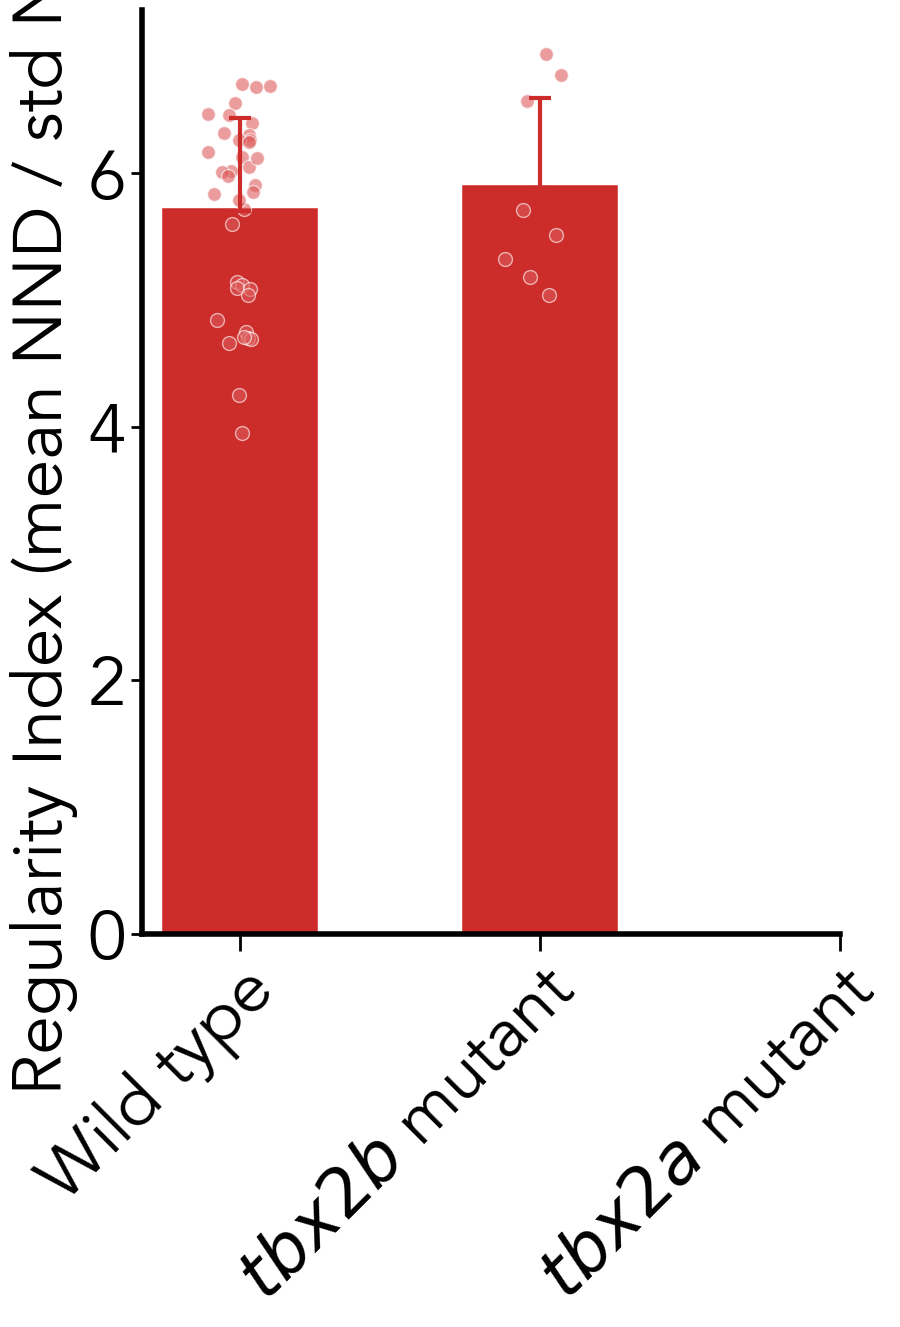

In [23]:
import os
import numpy as np
import matplotlib.pyplot as plt

def load_ri_array(dPath, fPath, verbose=True):
    vals = []
    for fp in fPath:
        fn = os.path.join(dPath, fp, "ri.npy")
        if not os.path.exists(fn):
            if verbose:
                print("Missing:", fn)
            continue
        ri = np.load(fn)
        vals.append(float(np.ravel(ri)[0]))
    vals = np.asarray(vals, dtype=float)
    vals = vals[~np.isnan(vals)]
    return vals

# ----------------------------
# EDIT THESE LISTS (same as RI computation cell)
# ----------------------------

dPath_wt = "Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/wt/"
fPath_wt = [
      # '20250425_2ahetinx_5d_m2G_tdT_L08_002/', #tear in retina 
                '20250425_2ahetinx_5d_m2G_tdT_L08_004/',
                '20250425_2ahetinx_5d_m2G_tdT_L09_002/',
                '20250425_2ahetinx_5d_m2G_tdT_L09_004/',
                '20250425_2ahetinx_5d_m2G_tdT_L10_002/',
                '20250425_2ahetinx_5d_m2G_tdT_L10_004/',
                # '20250425_2ahetinx_5d_m2G_tdT_L11_002', too curved 
                '20250425_2ahetinx_5d_m2G_tdT_L12_002/',
                # '20250425_2ahetinx_5d_m2G_tdT_L13_002', too curved 
                # '20250425_5dpf_tbx2ahetinx_m2G_tdT_L01_002', #ISSUE
                #'20250425_5dpf_tbx2ahetinx_m2G_tdT_L01_004', too curved 
                #'20250425_5dpf_tbx2ahetinx_m2G_tdT_L02_002',  blurred 
                '20250425_5dpf_tbx2ahetinx_m2G_tdT_L02_004/',
                '20250425_5dpf_tbx2ahetinx_m2G_tdT_L03_002/',
                '20250425_5dpf_tbx2ahetinx_m2G_tdT_L03_004/',
                '20250425_5dpf_tbx2ahetinx_m2G_tdT_L04_002/',
                '20250425_5dpf_tbx2ahetinx_m2G_tdT_L04_004/',
                # '20250425_5dpf_tbx2ahetinx_m2G_tdT_L05_002', #ISSUE 
                '20250425_5dpf_tbx2ahetinx_m2G_tdT_L05_004/',
                '20250425_5dpf_tbx2ahetinx_m2G_tdT_L06_002/',
                '20250425_5dpf_tbx2ahetinx_m2G_tdT_L07_002/',
                '20250425_5dpf_tbx2ahetinx_m2G_tdT_L07_004/',
                '220250818_5d_2ahetinx_tdT_m2G_L01_002/',
                '220250818_5d_2ahetinx_tdT_m2G_L02_002/',
                '220250818_5d_2ahetinx_tdT_m2G_L03_002/',
                 '220250818_5d_2ahetinx_tdT_m2G_L05_002/',
                '220250818_5d_2ahetinx_tdT_m2G_L05_004/',
                '220250818_5d_2ahetinx_tdT_m2G_L06_002/',
                '220250818_5d_2ahetinx_tdT_m2G_L07_002/',
                '220250818_5d_2ahetinx_tdT_m2G_L08_002/',
                '220250818_5d_2ahetinx_tdT_m2G_L08_004/',
                '220250818_5d_2ahetinx_tdT_m2G_L010_002/',
                '220250818_5d_2ahetinx_tdT_m2G_L011_002/',
                '220250818_5d_2ahetinx_tdT_m2G_L011_006/',
                # # '220250817_5d_m2G_tdT_2ahetinx_L12_002/', #mip not found
                '220250817_5d_m2G_tdT_2ahetinx_L12_006/',
                '220250817_5d_m2G_tdT_2ahetinx_L13_002/',
                '220250817_5d_m2G_tdT_2ahetinx_L14_002/',
                '220250817_5d_m2G_tdT_2ahetinx_L14_006/',
                # '220250723_2bhetinx_5d_tdT_m2G_L01_002',#no l seg curated
               # '220250723_2bhetinx_5d_tdT_m2G_L01_004', #no l seg curated
                # '220250723_2bhetinx_5d_tdT_m2G_L02_002',#no l seg curated
                # '220250723_2bhetinx_5d_tdT_m2G_L02_004',#no l seg curated
                '220250723_2bhetinx_5d_tdT_m2G_L03_002/', 
                '220250723_2bhetinx_5d_tdT_m2G_L03_004/',
                '220250723_2bhetinx_5d_tdT_m2G_L04_002/',
                '220250723_2bhetinx_5d_tdT_m2G_L04_004/',
                # '220250723_2bhetinx_5d_tdT_m2G_L06_002/', #holes
                # '220250723_2bhetinx_5d_tdT_m2G_L06_004/', #holes
                # '220250723_2bhetinx_5d_tdT_m2G_L08_002/', #curved
                '220250723_2bhetinx_5d_tdT_m2G_L08_004/',
                '220250723_2bhetinx_5d_tdT_m2G_L09_002/',
                # '220250723_2bhetinx_5d_tdT_m2G_L09_004/', #curved
                # '220250723_2bhetinx_5d_tdT_m2G_L13_002/', #curved
                # '220250723_2bhetinx_5d_tdT_m2G_L14_002/', #curved
                '220250723_2bhetinx_5d_tdT_m2G_L14_004/', #curated tiffs not there? 
                # '220250723_2bhetinx_5d_tdT_m2G_L15_004/', #curved
                # '220250723_2bhetinx_5d_tdT_m2G_L16_002/', #curved
                # '220250723_2bhetinx_5d_tdT_m2G_L16_004/', #curved
                # '220250723_2bhetinx_5d_tdT_m2G_L18_002/',#curved
                # '220250723_2bhetinx_5d_tdT_m2G_L18_002/',#curved
                # '220250723_2bhetinx_5d_tdT_m2G_L23_002/', #no l seg curated
                '220250723_2bhetinx_5d_tdT_m2G_L23_004/', #no l seg curated curated tiff not there?
                # '220250723_2bhetinx_5d_tdT_m2G_L24_002/', #no l seg curated
                # '220250723_2bhetinx_5d_tdT_m2G_L25_002/', #no m mip
                '220250723_2bhetinx_5d_tdT_m2G_L25_004/',
]

dPath_tbx2b = "Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/Tbx2bKO/"
fPath_tbx2b = [
             '220250723_2bhetinx_5d_tdT_m2G_L07_002/', #l NND DONE (CH 2026) 
                # '220250723_2bhetinx_5d_tdT_m2G_L07_004', #curved -  omit from analyzed data (CH 2026)
                 # '220250723_2bhetinx_5d_tdT_m2G_L26_004/', #no curated l seg
                '220250723_2bhetinx_5d_tdT_m2G_L26_002/', #l NND DONE (CH 2026)
                '220250723_2bhetinx_5d_tdT_m2G_L27_002/', #l NND DONE (CH 2026)
                '220250723_2bhetinx_5d_tdT_m2G_L28_002/', #l NND DONE (CH 2026)
                # '20251022_5d_2bhetinx_m2G_tdT_L24_002/',
                '20251022_5d_2bhetinx_m2G_tdT_L24_004/',
                '20251022_5d_2bhetinx_m2G_tdT_L26_002/',
                # '20251022_5d_2bhetinx_m2G_tdT_L26_004/', #kinda curved - omit (CH 2026)
                '20251022_5d_2bhetinx_m2G_tdT_L18_002/',
                '20251022_5d_2bhetinx_m2G_tdT_L18_004/',
                # '20251022_5d_tbx2bhetinx_m2G_tdT_L32_004', #curved and blurry -  omit from analyzed data (CH 2026)
                # '20251022_5d_tbx2bhetinx_m2G_tdT_L32_002',#too curved to analyze -  omit from analyzed data (CH 2026)
                # '20251022_5d_tbx2bhetinx_m2G_tdT_L32_004', #too curved to analyze -  omit from analyzed data (CH 2026)
                # '20251022_5d_tbx2bhetinx_m2G_tdT_L34_002', # #redo GFP Quant Analysis 
                # '20251022_5d_tbx2bhetinx_m2G_tdT_L34_004', #too curved MIP - omit from analyzed data (CH 2026)  
                # '20251022_5d_tbx2bhetinx_m2G_tdT_L38_002', # flat. 
                # '20251022_5d_tbx2bhetinx_m2G_tdT_L38_004', # curved -  omit from analyzed data (CH 2026)
                '20251022_5d_tbx2bhetinx_m2G_tdT_L41_002/',
                # '20251022_5d_tbx2bhetinx_m2G_tdT_L41_004', #curved - stretched effect -  omit from analyzed data (CH 2026)
                # '20251022_5d_tbx2bhetinx_m2G_tdT_L42_002', #CURVED - stretched effect -  omit from analyzed data (CH 2026)
                # '20251022_5d_tbx2bhetinx_m2G_tdT_L42_004', #CURVED - stretched effect -  omit from analyzed data (CH 2026)
]

dPath_tbx2a = "Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/Tbx2aKO/"
fPath_tbx2a = [
    '220250818_5d_2ahetinx_tdT_m2G_L04_002/',  #l NND DONE (CH 2026) 
    '220250818_5d_2ahetinx_tdT_m2G_L09_002/',  #l NND DONE (CH 2026) 
    '220250818_5d_2ahetinx_tdT_m2G_L09_006/',  #l NND DONE (CH 2026) 
    '20260226_5d_Tbx2ahetinx_tdT_m2G_L01_002/',  #l NND DONE (CH 2026) 
    '20260226_5d_Tbx2ahetinx_tdT_m2G_L01_004/',  #l NND DONE (CH 2026) 
    '20260226_5d_Tbx2ahetinx_tdT_m2G_L02_002/',  #l NND DONE (CH 2026) 
    '20260226_5d_Tbx2ahetinx_tdT_m2G_L02_004/',  #l NND DONE (CH 2026) 
    '20260226_5d_Tbx2ahetinx_tdT_m2G_L03_002/',  #l NND DONE (CH 2026) 
    '20260226_5d_Tbx2ahetinx_tdT_m2G_L03_004/',  #l NND DONE (CH 2026)  
    '20260226_5d_Tbx2ahetinx_tdT_m2G_L05_002/',  #l NND DONE (CH 2026) 
    '20260226_5d_Tbx2ahetinx_tdT_m2G_L05_004/',  #l NND DONE (CH 2026) 
]

# ----------------------------
# LOAD
# ----------------------------
ri_wt = load_ri_array(dPath_wt, fPath_wt, verbose=True)
ri_tbx2b = load_ri_array(dPath_tbx2b, fPath_tbx2b, verbose=True)
ri_tbx2a = load_ri_array(dPath_tbx2a, fPath_tbx2a, verbose=True)

print("\nLoaded n:")
print("  wt      =", len(ri_wt))
print("  tbx2bKO =", len(ri_tbx2b))
print("  tbx2aKO =", len(ri_tbx2a))

# ----------------------------
# PLOT (same bar + errorbar + jittered points style)
# ----------------------------
plotname = ''
fH, axH = plt.subplots(figsize=[9, 12])

groups = [ri_wt, ri_tbx2b, ri_tbx2a]
labels = ['Wild type', r'$\it{tbx2b}$ mutant', r'$\it{tbx2a}$ mutant']
geneColor = '#CC2C2A'
markers = ['o', 'o', 'o']

for i, (vals, mk) in enumerate(zip(groups, markers), start=1):
    jitter = np.random.randn(len(vals)) * 0.05

    pH = plt.bar(i, np.mean(vals), width=0.5, color=geneColor, linewidth=4, edgecolor=geneColor)
    pH = plt.errorbar(i, np.mean(vals), yerr=[[0], [np.std(vals)]],
                      ecolor=geneColor, elinewidth=3, capsize=8, capthick=3, zorder=9)
    pH = plt.scatter(np.ones(len(vals)) * i + jitter, vals,
                     color=lighten_color(geneColor, .75), zorder=8, marker=mk,
                     s=100, edgecolor=baseColor, linewidth=1, alpha=0.6)

for spine in axH.spines.values():
    spine.set_linewidth(4)

fontLabels = formatFigureMain(fH, axH, pH)

axH.set_xticks([1, 2, 3])
axH.set_xticklabels(labels, ha='right', rotation_mode='anchor')
axH.xaxis.set_tick_params(rotation=45, length=12)

axH.tick_params(axis='x', labelsize=50)
axH.tick_params(axis='y', labelsize=50)
axH.tick_params(axis='both', which='major', width=2)

axH.set_ylabel('Regularity Index (mean NND / std NND)', fontsize=50)
axH.yaxis.set_tick_params(length=8)

plt.style.use('default')
plt.show()

## Colors for PR Plotting 
```
            'RPC' : '#DADADA', # Retinal progenitor cell
            'PRPC' : '#dfdac8', # Photoreceptor progenitor cell
            'Cones_larval' : '#dcc360', #
            'Cones_adult' : '#ffd429', #
            
            
            #Photoreceptors
            'r' : '#747474', # Rods
            'u' : '#B540B7', # UV cones
            's' : '#4669F2', # S cones
            'm' : '#04CD22', # M cones
            'l' : '#CC2C2A', # L cones
            
            
            
            
            'm4': '#cdcd04', # opn1mws4-expressing M cones
            'HC' : '#FC7715', # Horizontal cells
            'BC_larval' : '#ccf2ff', # Bipolar cell (developing)
            'BC_adult' : '#663d00', # Bipolar cell (mature)
            'onBC': '#ccf2ff', # on bipolar cells
            'offBC': '#663d00', # off bipolar cells
            'AC_larval' : '#3DF591', # Amacrine cell (developing)
            'ACgaba' : '#3DF5C3', #
            'ACgly' : '#56F53D', #
            'RGC_larval' : '#F53D59', # Retinal Ganglion cell (developing)
            'RGC_adult' : '#BB0622', # Retinal Ganglion cell (mature)
            'MGi' : '#EA9D81', # Muller glia (immature)
            'MG1' : '#A2644E', # Muller glia (mature)
```

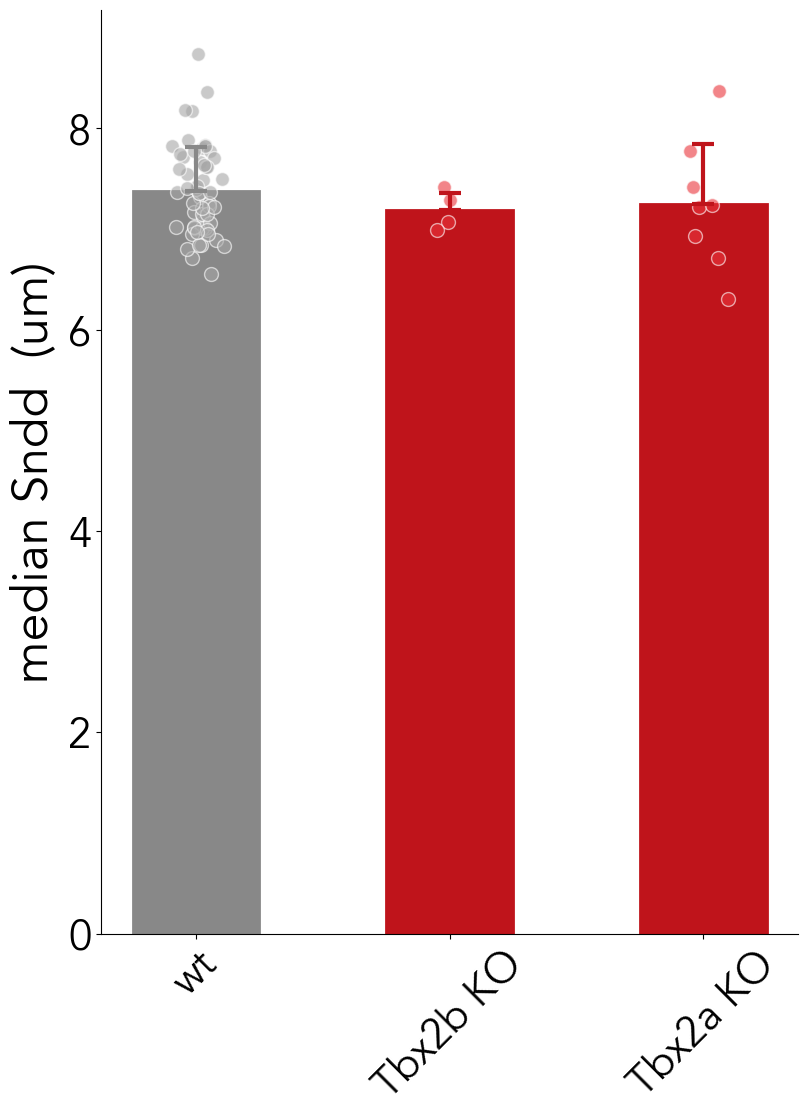

In [42]:

celltype = 'S'

#wildtype
dPath = "Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/wt/"
fPath = [
        '20250425_2ahetinx_5d_m2G_s2C_L01_002/',
        '20250425_2ahetinx_5d_m2G_s2C_L01_004/',
        '20250425_2ahetinx_5d_m2G_s2C_L03_002/',
        '20250425_2ahetinx_5d_m2G_s2C_L04_002/', 
        '20250425_2ahetinx_5d_m2G_s2C_L04_004/',
        '20250425_2ahetinx_5d_m2G_s2C_L07_002/',
        '20250425_2ahetinx_5d_m2G_s2C_L07_004/',
        '20250425_2ahetinx_5d_m2G_s2C_L08_004/',
        '20250425_2ahetinx_5d_m2G_s2C_L09_002/',
        '20250425_2ahetinx_5d_m2G_s2C_L09_004/',
        '20250425_2ahetinx_5d_m2G_s2C_L10_002/',
        '20250425_2ahetinx_5d_m2G_s2C_L11_002/',
        '20250425_2ahetinx_5d_m2G_s2C_L11_004/',
        '20250425_2ahetinx_5d_m2G_s2C_L12_002/',
        '20250425_2ahetinx_5d_m2G_s2C_L12_004/',
        '20250425_2ahetinx_5d_m2G_s2C_L13_002/',
        '20250425_2ahetinx_5d_m2G_s2C_L13_004/',
        '20250425_2ahetinx_5d_m2G_s2C_L14_002/',
        '20250716_5d_m2G_s2C_2ahetinx_L06_002/',
        '20250716_5d_m2G_s2C_2ahetinx_L06_004/',
        '20250716_5dp_tbx2ahetinx_s2C_m2G_L09_002/',
        '20250716_5dp_tbx2ahetinx_s2C_m2G_L09_004/',
        '20250716_5dp_tbx2ahetinx_s2C_m2G_L10_002/',
        '20250716_5dp_tbx2ahetinx_s2C_m2G_L10_004/',
        '20250716_5dp_tbx2ahetinx_s2C_m2G_L11_002/',
        '20250716_5dp_tbx2ahetinx_s2C_m2G_L12_002/',
        '20250716_5dp_tbx2ahetinx_s2C_m2G_L13_002/',
        '20250716_5dp_tbx2ahetinx_s2C_m2G_L13_004/',
        '20250716_5dpf_tbx2ahetinx_s2C_m2G_L01_002/',
        "20250123_5dpf_tbx2bhetinx_s2C_m2G_L01_002/",
        "20250123_5dpf_tbx2bhetinx_s2C_m2G_L01_004/",
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L02_002/',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L02_004/',
        # '20250123_5dpf_tbx2bhetinx_s2C_m2G_L04_002/', #issue with M nnd
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L04_004/',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L05_002/',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L05_004/',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L06_002/',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L06_004/',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L07_002/',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L07_004/',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L08_002/',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L08_004/',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L09_004/' ,
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L10_002/',
        # '20250123_5dpf_tbx2bhetinx_s2C_m2G_L10_004/',  #issue with M nnd
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L11_002/',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L11_004/',
        '220250807_5dpf_2bhetinx_s2C_m2G_L01_002/',
        '220250807_5dpf_2bhetinx_s2C_m2G_L01_004/',
        '220250807_5dpf_2bhetinx_s2C_m2G_L02_002/',
        '220250807_5dpf_2bhetinx_s2C_m2G_L04_002/',
        # '220250807_5dpf_2bhetinx_s2C_m2G_L06_002/', #toocurved
        '220250807_5dpf_2bhetinx_s2C_m2G_L07_002/',
        '220250807_5dpf_2bhetinx_s2C_m2G_L07_004/',
        '220250807_5dpf_2bhetinx_s2C_m2G_L10_002/',
        #'220250807_5dpf_2bhetinx_s2C_m2G_L10_004', only m cones
        '220250807_5dpf_2bhetinx_s2C_m2G_L12_004/',
        '220250807_5dpf_2bhetinx_s2C_m2G_L14_002/',
        '220250807_5dpf_2bhetinx_s2C_m2G_L14_004/'
            ]

nndUMean_wt = np.empty((len(fPath),1))
nndUMean_wt[:]=np.NaN
i=0;
for filepath in fPath:
    nnd = np.load(dPath + filepath + celltype + '_nnd.npy')
    nndUMean_wt[i,0] = np.median(nnd) * 79.64/2048
    i=i+1;

 #TBX2B KO FILES
dPath =  "Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/Tbx2bKO/"
fPath = [
# '20250123_5dpf_tbx2bhetinx_s2C_m2G_L03_002'#issue with M nnd 
        # '20250123_5dpf_tbx2bhetinx_s2C_m2G_L03_004/', #issue with M nnd
        # '220250807_5dpf_2bhetinx_s2C_m2G_L05_003/', #issue with M nnd
        # '220250807_5dpf_2bhetinx_s2C_m2G_L05_005/', #issue with M nnd
        # '220250807_5dpf_2bhetinx_s2C_m2G_L08_002/', #issue with M nnd
        '220250807_5dpf_2bhetinx_s2C_m2G_L08_004/',
        # '220250807_5dpf_2bhetinx_s2C_m2G_L11_002/', #missing folder - FIND IT AND RUN ANALYSIS ON IT
        '220250807_5dpf_2bhetinx_s2C_m2G_L11_004/',
        '220250807_5dpf_2bhetinx_s2C_m2G_L13_002/',
        '220250807_5dpf_2bhetinx_s2C_m2G_L13_004/',
        ]

nndUMean_tbx2a = np.empty((len(fPath),1))
nndUMean_tbx2a[:]=np.NaN
i=0;
for filepath in fPath:
    nnd = np.load(dPath + filepath + celltype + '_nnd.npy')
    nndUMean_tbx2a[i,0] = np.median(nnd) * 79.64/2048
    i=i+1;

#Tbx2a KO Samples     
dPath =  "Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/Tbx2aKO/"
fPath = [
        '20250425_2ahetinx_5d_m2G_s2C_L06_002/',
        '20250716_5d_m2G_s2C_2ahetinx_L03_002/',
        '20250716_5d_m2G_s2C_2ahetinx_L03_004/',
        '20250716_5d_m2G_s2C_2ahetinx_L05_002/',
        '20250716_5d_m2G_s2C_2ahetinx_L05_004/',
        '20250716_5dp_tbx2ahetinx_s2C_m2G_L08_002/',
        '20250716_5dp_tbx2ahetinx_s2C_m2G_L08_004/',
        '20250716_5dpf_tbx2ahetinx_s2C_m2G_L02_002/',
        ] 

nndUMean_tbx2b = np.empty((len(fPath),1))
nndUMean_tbx2b[:]=np.NaN
i=0;
for filepath in fPath:
    nnd = np.load(dPath + filepath + celltype + '_nnd.npy')
    nndUMean_tbx2b[i,0] = np.median(nnd) * 79.64/2048
    i=i+1;



plotname = ''
fH, axH = plt.subplots(figsize= [9,12])

i = 0
for nndM,geneColor,geneMarker in zip([nndUMean_wt,nndUMean_tbx2a,nndUMean_tbx2b],['#888888','#BF141B','#BF141B'],['o','o','o']):
    i = i+1
    jitter = np.random.randn(len(nndM))*0.05
    pH = plt.bar(i, np.mean(nndM), width=0.5, color=geneColor, linewidth = 2, edgecolor = geneColor);
    pH = plt.errorbar(i, np.mean(nndM), yerr = [[0],[np.std(nndM)]], ecolor=geneColor, elinewidth=3, capsize=8, capthick=3, zorder=9)
    pH = plt.scatter(np.ones(len(nndM))*i+jitter, nndM,
             color=lighten_color(geneColor,.75), zorder=8, marker = geneMarker, s=100, edgecolor=baseColor, linewidth=1, alpha = 0.6);

fontLabels = formatFigureMain(fH, axH, pH)
axH.set_xticks([1,2,3]);
axH.set_xticklabels(['wt','Tbx2b KO','Tbx2a KO']);
axH.xaxis.set_tick_params(rotation=45)
# axH.set_ylim([0,300]); # tbx2
axH.set_ylabel('median {0}ndd  (um)'.format(celltype), fontproperties=fontLabels)
plt.show()


#### Violin plots

TypeError: 'AxesSubplot' object is not subscriptable

Text(0, 0.5, 'Rndd  (um)')

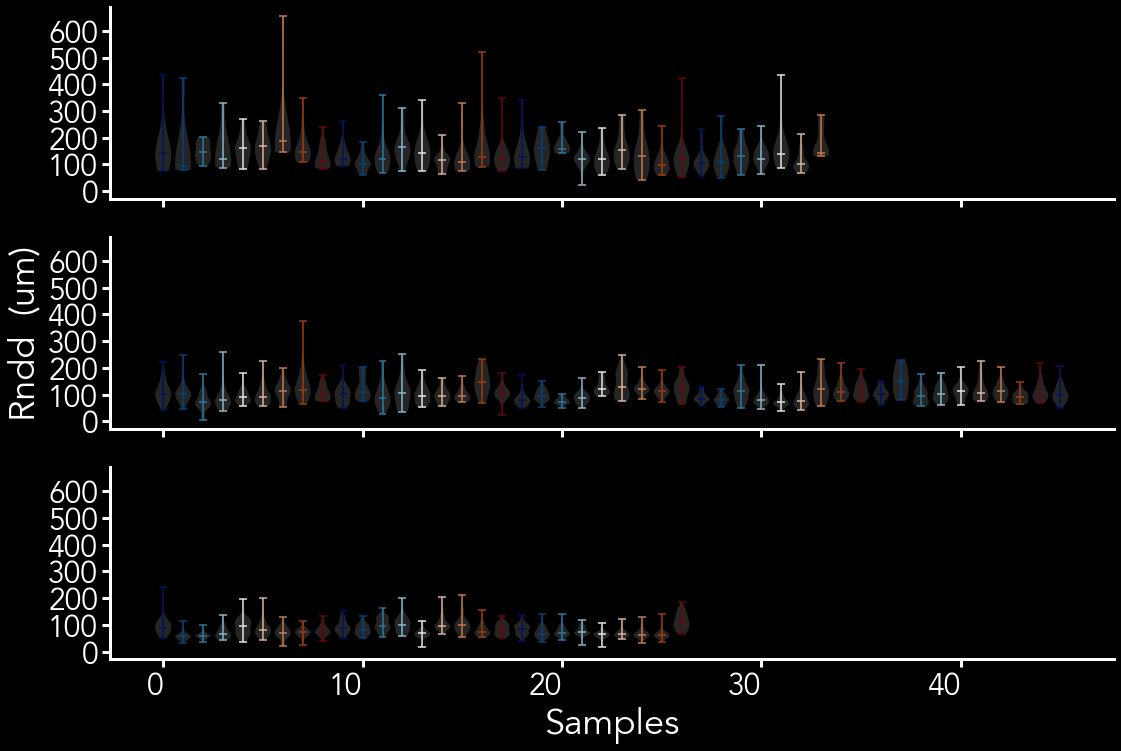

In [281]:
celltype = 'R'


plotname = ''
fH, axH = plt.subplots(3,1,figsize= [18,12], sharey=True, sharex = True)


dPath = '/Users/angueyraaristjm/Library/CloudStorage/OneDrive-NationalInstitutesofHealth/zf/Analysis/CRtbx2F0s/xOGs1C/wt/'
fPath = [
'20200821_5dpf_xOG_s1mCh_uninj_i05b/',
# '20200821_5dpf_xOG_s1mCh_uninj_i05d/',
# '20200821_5dpf_xOG_s1mCh_uninj_i06b/',
# '20200821_5dpf_xOG_s1mCh_uninj_i06d/',
'20200821_5dpf_xOG_s1mCh_uninj_i101b/',
# '20200821_5dpf_xOG_s1mCh_uninj_i101d/',
'20200821_5dpf_xOG_s1mCh_uninj_i102b/',
'20200821_5dpf_xOG_s1mCh_uninj_i103b/',
'20200821_5dpf_xOG_s1mCh_uninj_i104b/',
'20200821_5dpf_xOG_s1mCh_uninj_i104d/',
'20201113_5dpf_xOG_s1mCh_uninj_i06b/',
'20201113_5dpf_xOG_s1mCh_uninjected_i12b/',
'20201113_5dpf_xOG_s1mCh_uninjected_i12d/',
'20201113_5dpf_xOG_s1mCh_uninjected_i13b/',
'20201113_5dpf_xOG_s1mCh_uninjected_i15b/',
'20201113_5dpf_xOG_s1mCh_uninjected_i15d/',
'20210514_5dpf_xOG_s1C_uninj_L01b_withDAPI/',
'20210514_5dpf_xOG_s1C_uninj_L05b_withDAPI/',
'20210514_5dpf_xOG_s1C_uninj_L07b_withDAPI/',
'20221026_5dpf_xOG_s1C_wt_L01_002/',
'20221026_5dpf_xOG_s1C_wt_L01_004/',
'20221026_5dpf_xOG_s1C_wt_L02_002/',
'20221026_5dpf_xOG_s1C_wt_L03_002/',
'20221026_5dpf_xOG_s1C_wt_L03_004/',
'20221026_5dpf_xOG_s1C_wt_L04_002/',
'20221026_5dpf_xOG_s1C_wt_L04_004/',
'20221026_5dpf_xOG_s1C_wt_L05_002/',
'20221026_5dpf_xOG_s1C_wt_L05_004/',
'20221026_5dpf_xOG_s1C_wt_L06_002/',
# '20221026_5dpf_xOG_s1C_wt_L07_002/',
'20221026_5dpf_xOG_s1C_wt_L07_004/',
'20221026_5dpf_xOG_s1C_wt_L08_002/',
'20221026_5dpf_xOG_s1C_wt_L08_004/',
'20221026_5dpf_xOG_s1C_wt_L09_002/',
'20221026_5dpf_xOG_s1C_wt_L09_004/',
'20221026_5dpf_xOG_s1C_wt_L10_002/',
'20221026_5dpf_xOG_s1C_wt_L10_004/',
'20221026_5dpf_xOG_s1C_wt_L11_002/',
'20221026_5dpf_xOG_s1C_wt_L12_002/',
]


i=0;
for filepath in fPath:
    nnd = np.load(dPath + filepath + celltype + '_nnd.npy')
    vp = axH[0].violinplot(dataset=nnd,positions=[i], widths=.8, showextrema=True, showmedians=True)
    for body in vp['bodies']:
        body.set_facecolor(zfC[celltype])
    i=i+1;


dPath = '/Users/angueyraaristjm/Library/CloudStorage/OneDrive-NationalInstitutesofHealth/zf/Analysis/CRtbx2F0s/xOGs1C/tbx2a/'
fPath = [
'20200821_5dpf_xOG_s1mCh_CRtbx2a_i05b/',
'20200821_5dpf_xOG_s1mCh_CRtbx2a_i05d/',
'20200821_5dpf_xOG_s1mCh_CRtbx2a_i06b/',
'20200821_5dpf_xOG_s1mCh_CRtbx2a_i06d/',
'20200821_5dpf_xOG_s1mCh_CRtbx2a_i07b/',
'20200821_5dpf_xOG_s1mCh_CRtbx2a_i07d/',
'20200821_5dpf_xOG_s1mCh_CRtbx2a_i08b/',
'20200821_5dpf_xOG_s1mCh_CRtbx2a_i08d/',
'20200821_5dpf_xOG_s1mCh_CRtbx2a_i09b/',
'20200821_5dpf_xOG_s1mCh_CRtbx2a_i09d/',
'20200821_5dpf_xOG_s1mCh_CRtbx2a_i10b/',
'20200821_5dpf_xOG_s1mCh_CRtbx2a_i10d/',
'20200821_5dpf_xOG_s1mCh_CRtbx2a_i11b/',
'20200821_5dpf_xOG_s1mCh_CRtbx2a_i11d/',
'20210514_5dpf_xOG_s1C_CRtbx2a_L01b/',
'20210514_5dpf_xOG_s1C_CRtbx2a_L02b/',
'20210514_5dpf_xOG_s1C_CRtbx2a_L03b/',
'20210514_5dpf_xOG_s1C_CRtbx2a_L04b/',
'20210514_5dpf_xOG_s1C_CRtbx2a_L05b/',
'20210514_5dpf_xOG_s1C_CRtbx2a_L06b/',
'20210514_5dpf_xOG_s1C_CRtbx2a_L07b/',
'20210514_5dpf_xOG_s1C_CRtbx2a_L07d/',
'20210514_5dpf_xOG_s1C_CRtbx2a_L08b/',
'20210514_5dpf_xOG_s1C_CRtbx2a_L08d/',
'20210514_5dpf_xOG_s1C_CRtbx2a_L09b/',
'20210514_5dpf_xOG_s1C_CRtbx2a_L10b/',
'20210514_5dpf_xOG_s1C_CRtbx2a_L11b/',
'20210514_5dpf_xOG_s1C_CRtbx2a_L11d/',
'20210514_5dpf_xOG_s1C_CRtbx2a_L12b/',
'20210514_5dpf_xOG_s1C_CRtbx2a_L13b/',
'20210514_5dpf_xOG_s1C_CRtbx2a_L13d/',
'20210514_5dpf_xOG_s1C_CRtbx2a_L14b/',
'20210514_5dpf_xOG_s1C_CRtbx2a_L15b/',
'20221026_5dpf_xOG_s1C_tbx2aF0_L01_002/',
'20221026_5dpf_xOG_s1C_tbx2aF0_L01_004/',
'20221026_5dpf_xOG_s1C_tbx2aF0_L02_002/',
'20221026_5dpf_xOG_s1C_tbx2aF0_L02_004/',
'20221026_5dpf_xOG_s1C_tbx2aF0_L03_002/',
'20221026_5dpf_xOG_s1C_tbx2aF0_L05_002/',
'20221026_5dpf_xOG_s1C_tbx2aF0_L05_004/',
'20221026_5dpf_xOG_s1C_tbx2aF0_L06_002/',
'20221026_5dpf_xOG_s1C_tbx2aF0_L06_004/',
'20221026_5dpf_xOG_s1C_tbx2aF0_L07_002/',
'20221026_5dpf_xOG_s1C_tbx2aF0_L07_004/',
'20221026_5dpf_xOG_s1C_tbx2aF0_L08_002/',
'20221026_5dpf_xOG_s1C_tbx2aF0_L08_004/',
]


i=0;
for filepath in fPath:
    nnd = np.load(dPath + filepath + celltype + '_nnd.npy')
    vp = axH[1].violinplot(dataset=nnd,positions=[i], widths=.8, showextrema=True, showmedians=True)
    for body in vp['bodies']:
        body.set_facecolor(zfC[celltype])
    i=i+1;

    
dPath = '/Users/angueyraaristjm/Library/CloudStorage/OneDrive-NationalInstitutesofHealth/zf/Analysis/CRtbx2F0s/xOGs1C/tbx2b/'
fPath = [
'20201113_5dpf_xOG_s1mCh_CRtbx2b_i09b/',
'20201113_5dpf_xOG_s1mCh_CRtbx2b_i10b/',
'20201113_5dpf_xOG_s1mCh_CRtbx2b_i10d/',
'20201113_5dpf_xOG_s1mCh_CRtbx2b_i12b/',
'20201113_5dpf_xOG_s1mCh_CRtbx2b_i12d/',
'20201113_5dpf_xOG_s1mCh_CRtbx2b_i13b/',
'20201113_5dpf_xOG_s1mCh_CRtbx2b_i13d/',
# '20201113_5dpf_xOG_s1mCh_CRtbx2b_i14b/',
'20221026_5dpf_xOG_s1C_tbx2bF0_L01_002/',
'20221026_5dpf_xOG_s1C_tbx2bF0_L01_004/',
'20221026_5dpf_xOG_s1C_tbx2bF0_L02_002/',
'20221026_5dpf_xOG_s1C_tbx2bF0_L02_004/',
# '20221026_5dpf_xOG_s1C_tbx2bF0_L03_002/',
# '20221026_5dpf_xOG_s1C_tbx2bF0_L03_004/',
'20221026_5dpf_xOG_s1C_tbx2bF0_L04_002/',
'20221026_5dpf_xOG_s1C_tbx2bF0_L04_004/',
'20221026_5dpf_xOG_s1C_tbx2bF0_L05_002/',
'20221026_5dpf_xOG_s1C_tbx2bF0_L06_002/',
'20221026_5dpf_xOG_s1C_tbx2bF0_L06_004/',
'20221026_5dpf_xOG_s1C_tbx2bF0_L07_002/',
'20221026_5dpf_xOG_s1C_tbx2bF0_L07_004/',
'20221026_5dpf_xOG_s1C_tbx2bF0_L08_002/',
'20221026_5dpf_xOG_s1C_tbx2bF0_L08_004/',
'20221026_5dpf_xOG_s1C_tbx2bF0_L09_002/',
'20221026_5dpf_xOG_s1C_tbx2bF0_L09_004/',
'20221026_5dpf_xOG_s1C_tbx2bF0_L10_002/',
'20221026_5dpf_xOG_s1C_tbx2bF0_L10_004/',
'20221026_5dpf_xOG_s1C_tbx2bF0_L11_002/',
'20221026_5dpf_xOG_s1C_tbx2bF0_L11_004/',
'20221026_5dpf_xOG_s1C_tbx2bF0_L12_002/',
]    

i=0;
for filepath in fPath:
    nnd = np.load(dPath + filepath + celltype + '_nnd.npy')
    vp = axH[2].violinplot(dataset=nnd,positions=[i], widths=.8, showextrema=True, showmedians=True)
    for body in vp['bodies']:
        body.set_facecolor(zfC[celltype])
    i=i+1;


    
    
fontLabels = formatFigureMain(fH, axH[0], pH)
fontLabels = formatFigureMain(fH, axH[1], pH)
fontLabels = formatFigureMain(fH, axH[2], pH)
axH[2].set_xlabel('Samples', fontproperties=fontLabels)
axH[1].set_ylabel('{0}ndd  (um)'.format(celltype), fontproperties=fontLabels)

In [245]:

    
# vp[i] = axH[2].violinplot(dataset=nnd,positions=[i], widths=.8, showextrema=False, showmedians=True)

SyntaxError: invalid syntax (987083096.py, line 1)

IndexError: list index out of range

# NDD on other photoreceptors (from labels layers)

In [ ]:
dPath = '/Users/angueyraaristjm/Documents/eelImaging/tempAnalysis/CRnr2e3F0s/xOGaCT/wt/'
fPath = '20220121_5dpf_xOG_aCT_wt_L01_002/'
lPath = 'R_seg_curated.tiff'

labelData = imread(dPath + fPath + lPath)
# labelData

centroidData = calculateCentroidsFromLabels(labelData)
centroidData

In [ ]:
fH, axH = plt.subplots(figsize= [16,16])


pH = axH.imshow(labelData, cmap='bone')
pH = axH.scatter(centroidData[:,0],centroidData[:,1], color=zfC['R'], zorder=8, marker = 'o', s=50, edgecolor=baseColor, linewidth=0.5, alpha = 0.99);

## <a id='voronoi'>Voronoi</a>
Nice visualization, not extremely useful by itself


> [Back to index](#Index)

In [ ]:
np.size(vorU.regions[1])

In [ ]:
dPath = "/Users/angueyraaristjm/Documents/eelImaging/tempAnalysis/photoArrays/"
fUName = "U_missing.csv"
fNName = "N_points.csv"
nucsTiff = '20220121_5dpf_xOG_aCT_nr2e3_L06_004' + '.tiff'


Nucs = plt.imread(dPath + nucsName)

df =  pd.read_csv(dPath + fUName)
df = df.drop(columns = 'index')
U=df.to_numpy()
U = U[:,[1,0]]
vorU = scipy.spatial.Voronoi(U)

df =  pd.read_csv(dPath + fNName)
df = df.drop(columns = 'index')
N=df.to_numpy()
N = N[:,[1,0]]
vorN = scipy.spatial.Voronoi(N)

vorN = scipy.spatial.Voronoi(np.append(U,N,axis=0))

plotname = ''
fH, axH = plt.subplots(figsize= [16,16])

pH = axH.imshow(imread(dPath + nucsTiff), cmap='bone')


pH = plt.scatter(U[:,0],U[:,1], color=zfC['U'], zorder=8, marker = 'o', s=50, edgecolor=baseColor, linewidth=0.5, alpha = .6);
pH = scipy.spatial.voronoi_plot_2d(vorU, ax = axH, show_points = False, show_vertices=False, line_colors=zfC['U'], line_width=2, line_alpha=0.6, point_size=2)


regions, vertices = voronoi_finite_polygons_2d(vorU)
# colorize
for region in regions:
    polygon = vertices[region]
    plt.fill(*zip(*polygon), alpha=0.1)
    
# pH = plt.scatter(N[:,0],N[:,1], color=zfC['actb2'], zorder=8, marker = 'o', s=50, edgecolor=baseColor, linewidth=0.5, alpha = .6);
# pH = voronoi_plot_2d(vorN, ax = axH, show_points = False, show_vertices=False, line_colors=zfC['actb2'], line_width=2, line_alpha=0.6, point_size=2)

formatFigureMain(fH, axH, pH);

axH.set_xlim([-100,1124])
axH.set_ylim([-100,1124])

def p2umfx(x, pos): # formatter function
    s = '{:.2f}'.format(np.round(x * p2um,decimals=2))
    return s

axH.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(p2umfx))
axH.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(p2umfx))

# savePath = '/Users/angueyraaristjm/Library/CloudStorage/OneDrive-NationalInstitutesofHealth/zf/Manuscripts/2021_zfConeRNAseq/newGeneFigures/temp/'
# plt.savefig(savePath + goi + "_counts.svg", transparent=True, format="svg", bbox_inches = "tight")

### Lloyd's algorithm to make distribution more even
- Wikipedia: [Lloyd's algorithm](https://en.wikipedia.org/wiki/Lloyd%27s_algorithm)
- Implementation: [github.com/duhaime/lloyd](https://github.com/duhaime/lloyd)
    - Modified to use image boundaries (plus buffer) as mask for voronoi polygons during Lloyd's relaxation
    - Could use voronoi polygons to shapes or labels layers in napari [linkhere](https://napari.org/stable/gallery/shapes_to_labels.html)
        - there will be problems with vertices at infinity [someInforHere](https://stackoverflow.com/questions/23901943/voronoi-compute-exact-boundaries-of-every-region)
    

In [ ]:
# field = Field(np.multiply(np.ones(np.shape(U)),512)+np.random.normal(size=np.shape(U))) # start near the center and expand
field = Field(U, buffer = 20) #start from original locations of UV cones

nIterations = 2
with tqdm(total=nIterations, file=sys.stdout) as progBar:
# run Lloyd relaxation on the field of points
    for i in np.arange(0,nIterations):
        field.relax()
        progBar.update(1)



# get the resulting point positions
Ui = field.get_points()

vorUi = scipy.spatial.Voronoi(Ui)

# boundedRegions,boundedVertices = voronoi_finite_polygons_2d(vorUi)
# vorUi.regions = boundedRegions
# vorUi.vertices = boundedVertices


plotname = ''
fH, axH = plt.subplots(figsize= [16,16])


pH = plt.scatter(U[:,0],U[:,1], color=zfC['U'], zorder=8, marker = 'o', s=50, edgecolor=baseColor, linewidth=0.5, alpha = .2);
pH = scipy.spatial.voronoi_plot_2d(vorU, ax = axH, show_points = False, show_vertices=False, line_colors=zfC['U'], line_width=2, line_alpha=0.2, point_size=2)

pH = plt.scatter(Ui[:,0],Ui[:,1], color=zfC['S'], zorder=8, marker = 'o', s=50, edgecolor=baseColor, linewidth=0.5, alpha = .8);
pH = scipy.spatial.voronoi_plot_2d(vorUi, ax = axH, show_points = False, show_vertices=False, line_colors=zfC['S'], line_width=2, line_alpha=0.8, point_size=2)


border = [[0,0],[0,1024],[1024,1024],[1024,0]]
plt.fill(*zip(*border),alpha=0.5,facecolor='None',edgecolor='r')


regions, vertices = voronoi_finite_polygons_2d(vorUi)
clip = PolygonClipper()
# colorize
for region in regions:
    polygon = vertices[region]
    clipped = clip(polygon,border)
    plt.fill(*zip(*clipped), alpha=0.5)





# pH = plt.scatter(N[:,0],N[:,1], color=zfC['actb2'], zorder=8, marker = 'o', s=50, edgecolor=baseColor, linewidth=0.5, alpha = .6);
# pH = voronoi_plot_2d(vorN, ax = axH, show_points = False, show_vertices=False, line_colors=zfC['actb2'], line_width=2, line_alpha=0.6, point_size=2)

formatFigureMain(fH, axH, pH);


axH.set_xlim([-1000,2124])
axH.set_ylim([-1000,2124])
    
    

In [ ]:
kdtUi = scipy.spatial.KDTree(Ui)
kN = 1
Uinnd = np.empty((len(Ui),kN))
Uinnd[:]=np.NaN



for n in range(0,len(Ui)):
    temp = kdtUi.query(Ui[n],kN+1)
    for k in range (0,kN):
        Uinnd[n,k] = temp[0][k+1]


plotname = ''
fH, axH = plt.subplots(figsize= [12,6])
    
for k in range (0,kN):
    pH = plt.hist(Unnd[:,k], bins=40, color=zfC['U'], zorder=8 , edgecolor=baseColor, linewidth=0.5, alpha = .8);
    pH = plt.hist(Uinnd[:,k], bins=40, color=zfC['S'], zorder=8 , edgecolor=baseColor, linewidth=0.5, alpha = .8);

axH.set_xlim([0,np.max((Unnd)*1.2)])

formatFigureMain(fH, axH, pH);
plt.show();

print ('\n')
for k in range (0,kN):
    print ('Median for {0}-NDD : {1:.2f} pixels'.format(k+1,np.median(Unnd[:,k])))
    print ('Median for {0}-NDD after Lloyd\'s relaxation : {1:.2f} pixels'.format(k+1,np.median(Uinnd[:,k])))

In [ ]:
U = nnd.Centroids
vorU = nnd.vor

#### Clipping polygon example

In [ ]:
plotname = ''
fH, axH = plt.subplots(figsize= [16,16])

# pH = axH.imshow(Nucs, cmap='bone')

pH = plt.scatter(U[:,0],U[:,1], color=zfC['U'], zorder=8, marker = 'o', s=50, edgecolor=baseColor, linewidth=0.5, alpha = .2);
pH = scipy.spatial.voronoi_plot_2d(vorU, ax = axH, show_points = False, show_vertices=False, line_colors=zfC['U'], line_width=2, line_alpha=0.8, point_size=2)

# pH = plt.scatter(Ui[:,0],Ui[:,1], color=zfC['S'], zorder=8, marker = 'o', s=50, edgecolor=baseColor, linewidth=0.5, alpha = .8);
# pH = scipy.spatial.voronoi_plot_2d(vorUi, ax = axH, show_points = False, show_vertices=False, line_colors=zfC['S'], line_width=2, line_alpha=0.8, point_size=2)

# polygon = vorUi.vertices[vorUi.regions[24]]
# polygon = field.voronoi.vertices[field.voronoi.regions[30]+field.voronoi.regions[0]]
polygon = field.voronoi.vertices[field.voronoi.regions[12]]
plt.fill(*zip(*polygon),alpha=0.5,facecolor='r',edgecolor='k')


border = field.get_bb_pointsClockwise()
# border = [[0,0],[0,1024],[1024,1024],[1024,0]]
plt.fill(*zip(*border),alpha=0.5,facecolor='None',edgecolor='r')

clip = PolygonClipper()
clipped = clip(polygon,border)

plt.fill(*zip(*clipped),alpha=0.5,facecolor='g')

axH.set_xlim([-200,1200])
axH.set_ylim([-200,1200])